# Fractura hidráulica: control óptimo del caudal de inyección

Notebook autocontenido del avance del proyecto (MA4703 Control Óptimo, primavera 2026). Calcula todo lo que reporta el
avance —dinámica en lazo abierto, Pontryagin contra el método directo y HJB—, corre sus pruebas y deja los resultados en
`salidas/`, en la misma carpeta que este archivo. No necesita ningún otro archivo.

## Cómo correrlo
1. **Julia 1.11**, con juliaup: en macOS o Linux, `curl -fsSL https://install.julialang.org | sh`; en Windows, lo que
   indica https://julialang.org/install/. Después, `juliaup add 1.11` y `juliaup default 1.11`.
2. **IJulia**, el kernel de Jupyter para Julia: `julia -e 'import Pkg; Pkg.add("IJulia")'`.
3. Abrir este notebook en Jupyter (`julia -e 'using IJulia; notebook(dir = pwd())'`, desde esta carpeta) o en VS Code
   con la extensión de Julia, elegir el kernel de Julia 1.11 y **correr todas las celdas en orden**.

La celda «Entorno» fija la versión de cada paquete en un entorno temporal. La primera vez los baja de internet y los
precompila, lo que puede tardar varios minutos; las corridas siguientes no usan la red.

## Qué deja en `salidas/`
- `resultados/`: los json de resultados de los objetivos 1, 3 y 4.
- `semilla/resultados-lectura.json`: las comprobaciones de lectura del modelo.
- `reporte/cifras.tex` y `reporte/figuras/*.tex`: las cifras y las figuras que compila el reporte.
- `figuras/*.png`: las mismas tres figuras, que además se muestran en el notebook.
- `beamer/datos/*.csv`: las curvas que anima la presentación.

La última celda compara las cifras recién calculadas con las del reporte entregado y da error si alguna difiere. Tres
cifras son ruido de redondeo (residuos del orden de $10^{-12}$ a $10^{-15}$) y cambian en la última cifra según el
computador: para esas basta el orden de magnitud, y la celda lo avisa con `RUIDO` sin dar error.


## Entorno

In [1]:
# Versiones exactas en un entorno temporal: sin red si la caché de paquetes alcanza, con red si no.
import Pkg
const VERSIONES = ["OrdinaryDiffEqVerner" => "1.14.0", "NLPModels" => "0.21.12", "NLPModelsIpopt" => "0.11.3",
                   "QuadGK" => "2.11.3", "JSON" => "1.9.0", "StaticArrays" => "1.9.22",
                   "Plots" => "1.41.7", "GR" => "0.73.27"]
Pkg.activate(; temp = true, io = devnull)
let specs = [Pkg.PackageSpec(; name, version) for (name, version) in VERSIONES]
    try
        Pkg.offline(true)
        Pkg.add(specs; io = devnull)
    catch
        Pkg.offline(false)
        Pkg.add(specs; io = devnull)
    end
end
using OrdinaryDiffEqVerner, NLPModels, NLPModelsIpopt, QuadGK, JSON, StaticArrays,
      LinearAlgebra, Printf, Random, Test
ENV["GKSwstype"] = "100"   # GR sin ventana: las figuras van al notebook y a PNG
import Plots

# Todo lo que escribe el notebook va a salidas/, en la carpeta del notebook.
const SALIDAS = joinpath(pwd(), "salidas")
mkpath(SALIDAS);

## Parámetros y modelo

In [2]:
Base.@kwdef struct Par
    n::Float64 = 2.0
    c::Float64 = 1.0
    η::Float64 = 0.2
    ℓ0::Float64 = 1.0
    P0::Float64 = 0.3
    T::Float64 = 2.0
    ℓd::Float64 = 1.7
    wT::Float64 = 10.0
    wp::Float64 = 1.0
    wq::Float64 = 0.2
    qmax::Float64 = 2.0
    Pref::Float64 = 0.0
end

con(p::Par; kw...) = Par(; (k => getfield(p, k) for k in fieldnames(Par))..., kw...)
comodict(p::Par) = Dict("n" => p.n, "c" => p.c, "eta" => p.η, "ell0" => p.ℓ0, "P0" => p.P0, "T" => p.T,
                        "Ld" => p.ℓd, "wT" => p.wT, "wp" => p.wp, "wq" => p.wq, "qmax" => p.qmax, "Pref" => p.Pref)

D(x, p) = p.c + x[1]^2
x2(y) = SVector(y[1], y[2])
ζ2(y) = SVector(y[3], y[4])

function f(x, u, p)
    ℓ, P = x[1], x[2]
    F = ℓ^(p.n / 2) * P^p.n
    SVector(F, (u - p.η * ℓ * P - 2ℓ * P * F) / D(x, p))
end

# Con P = 0 se usa n·ℓ^(n/2)·P^(n-1), no nF/P.
function ∂f(x, u, p)
    ℓ, P, n = x[1], x[2], p.n
    d = D(x, p)
    F = ℓ^(n / 2) * P^n
    Fℓ = n / 2 * ℓ^(n / 2 - 1) * P^n
    FP = n * ℓ^(n / 2) * P^(n - 1)
    h = (u - p.η * ℓ * P - 2ℓ * P * F) / d
    Rℓ = p.η * P + 2P * F + 2ℓ * P * Fℓ
    RP = p.η * ℓ + 2ℓ * F + 2ℓ * P * FP
    SMatrix{2, 2}(Fℓ, -Rℓ / d - 2ℓ * h / d, FP, -RP / d)
end

L(x, u, p) = (p.wp * (x[2] - p.Pref)^2 + p.wq * u^2) / 2
∂L(x, p) = SVector(zero(x[2]), p.wp * (x[2] - p.Pref))
Φ(x, p) = p.wT * (x[1] - p.ℓd)^2 / 2
H(x, ζ, u, p) = (v = f(x, u, p); ζ[1] * v[1] + ζ[2] * v[2] - L(x, u, p))
ulibre(x, ζ, p) = ζ[2] / (p.wq * D(x, p))
ustar(x, ζ, p) = clamp(ulibre(x, ζ, p), 0.0, p.qmax)

ustar (generic function with 1 method)

## Integrador y lazo abierto

In [3]:
function integrar(g, y0, tspan; kw...)
    s = solve(ODEProblem{false}((y, _, t) -> g(y, t), y0, tspan), Vern9(); reltol = 1e-12, abstol = 1e-14, kw...)
    s.retcode == ReturnCode.Success || error("integrar: $(s.retcode)")
    s
end

# RK4 de paso fijo con salida densa de Hermite cúbica, solo para avance y adjunto (T5, medido el 13-oct sobre q200):
# PASOS_RK pasos en todo el horizonte, m = cld(PASOS_RK, N) por tramo: en q200 (m = 4), J cambia 5e-14 al duplicarlo
# y difiere 6e-14 del de Vern9. Con m fijo por tramo, el control constante (N = 1) quedaba en 4 pasos. Sirve hacia atrás.
const PASOS_RK = 800

struct TramoRK{V}
    t0::Float64
    h::Float64
    u::Vector{V}
    du::Vector{V}
end

function (s::TramoRK)(τ)
    m = length(s.u) - 1
    i = clamp(floor(Int, (τ - s.t0) / s.h), 0, m - 1)
    θ = (τ - (s.t0 + i * s.h)) / s.h
    h00 = (1 + 2θ) * (1 - θ)^2
    h10 = θ * (1 - θ)^2
    h01 = θ^2 * (3 - 2θ)
    h11 = θ^2 * (θ - 1)
    h00 * s.u[i+1] + (h10 * s.h) * s.du[i+1] + h01 * s.u[i+2] + (h11 * s.h) * s.du[i+2]
end

function rk4(g::G, y0, (ta, tb), m) where {G}
    h = (tb - ta) / m
    y = y0
    u, du = [y0], typeof(y0)[]
    for i in 0:m-1
        t = ta + i * h
        k1 = g(y, t)
        k2 = g(y + h / 2 * k1, t + h / 2)
        k3 = g(y + h / 2 * k2, t + h / 2)
        k4 = g(y + h * k3, t + h)
        y = y + h / 6 * (k1 + 2k2 + 2k3 + k4)
        push!(du, k1)
        push!(u, y)
    end
    push!(du, g(y, tb))
    TramoRK(ta, h, u, du)
end

function simular(p, U, T, npts)
    s = integrar((y, _) -> push(f(y, U, p), y[1] * y[2]), SVector(p.ℓ0, p.P0, 0.0), (0.0, T);
                 saveat = range(0.0, T, length = npts))
    ℓ, P, I = (getindex.(s.u, i) for i in 1:3)
    (t = s.t, ℓ, P, S = (p.c .+ ℓ .^ 2) .* P, I)
end

simular (generic function with 1 method)

## Raíces

In [4]:
# Regula falsi de Illinois: superlineal y siempre dentro del intervalo.
function raiz(g, a, b; xtol = 4eps(), maxit = 200)
    fa, fb = g(a), g(b)
    fa == 0 && return a
    fb == 0 && return b
    sign(fa) != sign(fb) || throw(ArgumentError("raiz: sin cambio de signo en [$a, $b]"))
    lado = 0
    for _ in 1:maxit
        abs(b - a) ≤ xtol * max(1.0, abs(a), abs(b)) && break
        c = (a * fb - b * fa) / (fb - fa)
        (min(a, b) < c < max(a, b)) || (c = (a + b) / 2)
        fc = g(c)
        fc == 0 && return c
        if sign(fc) == sign(fb)
            b, fb = c, fc
            lado == -1 && (fa /= 2)
            lado = -1
        else
            a, fa = c, fc
            lado == 1 && (fb /= 2)
            lado = 1
        end
    end
    (a + b) / 2
end

# Newton 2×2 con Jacobiano por diferencias centradas y búsqueda lineal por mitades.
function jac_fd(F, z; δ = 1e-6)
    h1, h2 = δ * max(1.0, abs(z[1])), δ * max(1.0, abs(z[2]))
    e1, e2 = SVector(h1, 0.0), SVector(0.0, h2)
    hcat((F(z + e1) - F(z - e1)) / 2h1, (F(z + e2) - F(z - e2)) / 2h2)
end

function newton2(F, z0; tol = 1e-14, maxit = 50)
    z = SVector{2, Float64}(z0)
    r = F(z)
    for it in 0:maxit-1
        maximum(abs, r) ≤ tol && return (; u = collect(z), retcode = "Success", iter = it)
        Δ = jac_fd(F, z) \ r
        t = 1.0
        while true
            zn = z - t * Δ
            rn = F(zn)
            if maximum(abs, rn) < maximum(abs, r)
                z, r = zn, rn
                break
            end
            t /= 2
            t < 1e-6 && return (; u = collect(z), retcode = "Stalled", iter = it)
        end
    end
    (; u = collect(z), retcode = "MaxIters", iter = maxit)
end

newton2 (generic function with 1 method)

## Método directo: avance, adjunto e Ipopt

In [5]:
malla(p, N) = range(0.0, p.T, length = N + 1)

function avance(q, p)
    t = malla(p, length(q))
    m = cld(PASOS_RK, length(q))
    y = SVector(p.ℓ0, p.P0, 0.0)
    tramos = []
    for k in eachindex(q)
        s = rk4((z, _) -> push(f(z, q[k], p), L(z, q[k], p)), y, (t[k], t[k+1]), m)
        push!(tramos, s)
        y = s.u[end]
    end
    Φ(y, p) + y[3], identity.(tramos)
end

function adjunto(q, p, tramos)
    t = malla(p, length(q))
    m = cld(PASOS_RK, length(q))
    xT = tramos[end].u[end]
    ζ = SVector(-p.wT * (xT[1] - p.ℓd), 0.0)
    g = zeros(length(q))
    ζs = Vector{Any}(undef, length(q))
    for k in reverse(eachindex(q))
        xk = tramos[k]
        s = rk4(push(ζ, 0.0), (t[k+1], t[k]), m) do y, τ
            x = xk(τ)
            push(-∂f(x, q[k], p)' * x2(y) + ∂L(x, p), p.wq * q[k] - y[2] / D(x, p))
        end
        g[k] = -s.u[end][3]
        ζ = x2(s.u[end])
        ζs[k] = s
    end
    g, identity.(ζs)
end

costo_y_gradiente(q, p) = (r = avance(q, p); (r[1], adjunto(q, p, r[2])[1]))
gradiente(q, p) = costo_y_gradiente(q, p)[2]

struct Directo{M} <: AbstractNLPModel{Float64, Vector{Float64}}
    meta::NLPModelMeta{Float64, Vector{Float64}}
    counters::Counters
    p::Par
    B::M
end

Directo(p, B, θ0) = Directo(NLPModelMeta(size(B, 2); x0 = float.(θ0), lvar = zeros(size(B, 2)),
                                         uvar = fill(p.qmax, size(B, 2)), hess_available = false), Counters(), p, B)
NLPModels.obj(m::Directo, θ::AbstractVector) = avance(m.B * θ, m.p)[1]
NLPModels.grad!(m::Directo, θ::AbstractVector, g::AbstractVector) = (g .= m.B' * gradiente(m.B * θ, m.p))

const IPOPT = (print_level = 0, tol = 1e-12, limited_memory_max_history = 30, max_iter = 3000, honor_original_bounds = "yes")

const TOL_ACTIVA = 1e-6

function fijar_activas(θ, g, hi)
    arriba = findall(k -> 0 < hi - θ[k] ≤ TOL_ACTIVA && g[k] < 0, eachindex(θ))
    abajo = findall(k -> 0 < θ[k] ≤ TOL_ACTIVA && g[k] > 0, eachindex(θ))
    θ = copy(θ)
    θ[arriba] .= hi
    θ[abajo] .= 0.0
    θ, length(arriba) + length(abajo)
end

function ipopt_directo(p, B, θ0; kw...)
    st = ipopt(Directo(p, B, θ0); IPOPT..., kw...)
    θ, fijadas = fijar_activas(st.solution, B' * gradiente(B * st.solution, p), p.qmax)
    (; x = θ, fun = avance(B * θ, p)[1], fun_sin_fijar = avance(B * st.solution, p)[1], fijadas, exito = st.status == :first_order,
       status = st.status, iter = st.iter)
end

optimizar(p, N; q0 = zeros(N), kw...) = ipopt_directo(p, I(N), q0; kw...)

function diagnosticos(q, p)
    t = malla(p, length(q))
    J, tramos = avance(q, p)
    g, ζs = adjunto(q, p, tramos)
    m = (t[1:end-1] .+ t[2:end]) ./ 2
    x = [tramos[k](m[k]) for k in eachindex(q)]
    ζ = [ζs[k](m[k]) for k in eachindex(q)]
    Hs = [H(x[k], ζ[k], q[k], p) for k in eachindex(q)]
    brecha = [q[k] - ustar(x[k], ζ[k], p) for k in eachindex(q)]
    Pmin = minimum(minimum(tramos[k](s)[2] for s in range(t[k], t[k+1], length = 9)) for k in eachindex(q))
    xT = tramos[end].u[end]
    Dict("J" => J, "norma_grad_inf" => maximum(abs, g), "H_oscilacion" => maximum(Hs) - minimum(Hs),
         "H_medio" => sum(Hs) / length(Hs), "pmp_brecha_max" => maximum(abs, brecha), "q_min" => minimum(q),
         "q_max" => maximum(q), "q_ultimo" => q[end], "n_cota_inf" => count(≤(1e-12), q),
         "n_cota_sup" => count(≥(p.qmax - 1e-12), q), "P_min" => Pmin, "ell_T" => xT[1], "P_T" => xT[2])
end

diagnosticos (generic function with 1 method)

## Disparo sobre el sistema extremal

In [6]:
const TOL_RESIDUO = 1e-10

function extremal(z0, p)
    integrar(SVector(p.ℓ0, p.P0, z0[1], z0[2], 0.0), (0.0, p.T)) do y, _
        x, ζ = x2(y), ζ2(y)
        u = ustar(x, ζ, p)
        vcat(f(x, u, p), -∂f(x, u, p)' * ζ + ∂L(x, p), SVector(L(x, u, p)))
    end
end

function residuo(z0, p, variante)
    yT = extremal(z0, p).u[end]
    variante == :penalizado ? SVector(yT[3] + p.wT * (yT[1] - p.ℓd), yT[4]) : SVector(yT[1] - p.ℓd, yT[4])
end

function conmutaciones(s, p; npts = 4001)
    t = range(0.0, p.T, length = npts)
    w(τ) = (y = s(τ); ulibre(x2(y), ζ2(y), p))
    W = w.(t)
    out = Float64[]
    for nivel in (0.0, p.qmax), i in 1:npts-1
        sign(W[i] - nivel) * sign(W[i+1] - nivel) < 0 && push!(out, raiz(τ -> w(τ) - nivel, t[i], t[i+1]))
    end
    sort(filter(τ -> p.T - τ > 1e-6, out))
end

function resolver(p, semilla, variante = :penalizado)
    variante in (:penalizado, :terminal) || throw(ArgumentError(string(variante)))
    r = newton2(z -> residuo(z, p, variante), semilla)
    s = extremal(r.u, p)
    yT = s.u[end]
    J = yT[5] + (variante == :penalizado ? Φ(yT, p) : 0.0)
    Hs = [(y = s(τ); H(x2(y), ζ2(y), ustar(x2(y), ζ2(y), p), p)) for τ in range(0.0, p.T, length = 401)]
    res = residuo(r.u, p, variante)
    Dict("exito" => maximum(abs, res) < TOL_RESIDUO, "mensaje" => r.retcode, "z0" => r.u, "J" => J,
         "ell_T" => yT[1], "P_T" => yT[2], "zeta_ell_T" => yT[3], "norma_residuo" => maximum(abs, res),
         "H_oscilacion" => maximum(Hs) - minimum(Hs), "conmutaciones" => conmutaciones(s, p), "sol" => s)
end

resolver (generic function with 2 methods)

## Comparaciones con controles simples

In [7]:
const N_RAMPA = 200

Jconst(U, p) = avance([U], p)[1]
ℓTconst(U, p) = avance([U], p)[2][end].u[end][1]
info(q, J; extra...) = Dict{String, Any}("J" => J, "U_min" => minimum(q), "U_max" => maximum(q),
                                         (string(k) => v for (k, v) in extra)...)

function constante_factible(p)
    U = raiz(U -> ℓTconst(U, p) - p.ℓd, 0.0, p.qmax)
    U, ℓTconst(U, p)
end

function mejor_constante(p)
    U = raiz(U -> gradiente([U], p)[1], 0.0, p.qmax)
    info([U], Jconst(U, p); U, toca_cota = min(U, p.qmax - U) < 1e-8)
end

function base_rampa(p)
    t = malla(p, N_RAMPA)
    s = (t[1:end-1] .+ t[2:end]) ./ 2 ./ p.T
    [1 .- s s]
end

function mejor_rampa(p)
    B = base_rampa(p)
    U0 = mejor_constante(p)["U"]
    st = ipopt_directo(p, B, [U0, U0])
    a, b = st.x
    info(B * [a, b], st.fun; a, b, escalonada_N = N_RAMPA, toca_cota = any(min.([a, b], p.qmax .- [a, b]) .< 1e-8))
end

function volumen_optimo(p, semilla)
    s = resolver(p, semilla)["sol"]
    quadgk(τ -> (y = s(τ); ustar(x2(y), ζ2(y), p)), 0.0, p.T; rtol = 1e-13)[1]
end

function constante_igual_volumen(p, semilla)
    V = volumen_optimo(p, semilla)
    U = V / p.T
    info([U], Jconst(U, p); U, volumen = V)
end

function desglose(q, p)
    t = malla(p, length(q))
    h = p.T / length(q)
    J, tramos = avance(q, p)
    xT = tramos[end].u[end]
    presion = sum(quadgk(τ -> p.wp * (tramos[k](τ)[2] - p.Pref)^2 / 2, t[k], t[k+1]; atol = 1e-15, rtol = 1e-13)[1]
                  for k in eachindex(q))
    Dict("J" => J, "terminal" => Φ(xT, p), "presion" => presion, "control" => p.wq * sum(abs2, q) * h / 2,
         "volumen" => sum(q) * h, "ell_T" => xT[1], "P_T" => xT[2])
end

desglose (generic function with 1 method)

## HJB por semi-Lagrangiano

In [8]:
function ubicar(e, X, modo)
    modo in (:extrapolar, :recortar) || throw(ArgumentError(string(modo)))
    X = modo == :recortar ? clamp(X, e[1], e[end]) : X
    s = (X - e[1]) / (e[2] - e[1])
    i = clamp(floor(Int, s), 0, length(e) - 2)
    i + 1, s - i
end

evaluar(V, (i, s, j, r)) = (1 - s) * (1 - r) * V[i, j] + s * (1 - r) * V[i+1, j] + (1 - s) * r * V[i, j+1] + s * r * V[i+1, j+1]
interpolar(V, ejes, X0, X1, bordes) = evaluar(V, (ubicar(ejes[1], X0, bordes[1])..., ubicar(ejes[2], X1, bordes[2])...))

function pie(f, x, u, dt)
    k1 = f(x, u)
    k2 = f((x[1] + dt / 2 * k1[1], x[2] + dt / 2 * k1[2]), u)
    x[1] + dt * k2[1], x[2] + dt * k2[2]
end

function tabla(f, costo, x, u, dt, ejes, bordes)
    y = pie(f, x, u, dt)
    (ubicar(ejes[1], y[1], bordes[1])..., ubicar(ejes[2], y[2], bordes[2])..., dt / 2 * (costo(x, u) + costo(y, u)))
end

# where {F, C}: f y costo solo se pasan, y sin esto Julia no especializa en ellos; el bucle de abajo
# queda con despacho dinámico y va ~25 veces más lento (medido el 13-oct).
function semi_lagrangiano(f::F, costo::C, g, ejes, controles, T, nt, bordes) where {F, C}
    dt = T / nt
    nodos = collect(Iterators.product(ejes...))
    tab = reshape([tabla(f, costo, x, u, dt, ejes, bordes) for u in controles, x in nodos], length(controles), :)
    V = Vector{Matrix{Float64}}(undef, nt + 1)
    pol = Vector{Matrix{Float64}}(undef, nt)
    V[nt+1] = g.(nodos)
    for k in nt-1:-1:0
        Vsig = V[k+2]
        Vk, Pk = similar(Vsig), similar(Vsig)
        # El primer mínimo, como findmin: desigualdad estricta.
        @inbounds for j in axes(tab, 2)
            mejor, a = Inf, 1
            for i in axes(tab, 1)
                e = tab[i, j]
                q = e[5] + evaluar(Vsig, e)
                if q < mejor
                    mejor, a = q, i
                end
            end
            Vk[j] = mejor
            Pk[j] = controles[a]
        end
        V[k+1], pol[k+1] = Vk, Pk
    end
    V, pol
end

function solucion(f, costo, g, ejes, controles, T, nt, bordes)
    V, pol = semi_lagrangiano(f, costo, g, ejes, controles, T, nt, bordes)
    (; V, politica = pol, f, costo, ejes, controles = collect(float.(controles)), T, nt, dt = T / nt, bordes)
end

# La ley se consulta en t ∈ [0, T): entre t y el nodo siguiente faltan δ = t_{k+1} − t, y se propaga δ, no un dt
# completo (H01 de la revisión del 16-oct). En los nodos δ = dt y coincide con la política de la tabla.
function feedback(sol, t, x)
    0 <= t < sol.T || throw(ArgumentError("feedback: t = $t fuera de [0, T)"))
    k = min(floor(Int, t / sol.dt + 1e-9), sol.nt - 1)
    δ = (k + 1) * sol.dt - t
    Vsig = sol.V[k+2]
    mejor, umejor = Inf, sol.controles[1]
    for u in sol.controles
        e = tabla(sol.f, sol.costo, x, u, δ, sol.ejes, sol.bordes)
        q = e[5] + evaluar(Vsig, e)
        if q < mejor
            mejor, umejor = q, u
        end
    end
    umejor
end

valor(sol, k, x) = interpolar(sol.V[k+1], sol.ejes, x[1], x[2], sol.bordes)

const BORDES_FRACTURA = (:extrapolar, :recortar)

function hjb_fractura(p, nl, nP, nt, nu; lmax = 2.55, Pmax = 1.2)
    ejes = (range(1.0, lmax, length = nl), range(0.0, Pmax, length = nP))
    solucion((x, u) -> f(x, u, p), (x, u) -> L(x, u, p), x -> Φ(x, p), ejes, range(0.0, p.qmax, length = nu),
             p.T, nt, BORDES_FRACTURA)
end

function simular_lazo(f, costo, g, ley, x0, T; n_sub = 400, n_rk = 5)
    h = T / n_sub
    dh = h / n_rk
    x = SVector{2, Float64}(x0)
    corriente = 0.0
    ts, Us, Xs = Float64[], Float64[], [x]
    campo(y, u) = push(SVector{2}(f(x2(y), u)), costo(x2(y), u))
    for m in 0:n_sub-1
        t = m * h
        u = ley(t, x)
        y = push(x, 0.0)
        for _ in 1:n_rk
            k1 = campo(y, u)
            k2 = campo(y + dh / 2 * k1, u)
            k3 = campo(y + dh / 2 * k2, u)
            k4 = campo(y + dh * k3, u)
            y = y + dh / 6 * (k1 + 2k2 + 2k3 + k4)
        end
        x = x2(y)
        corriente += y[3]
        push!(ts, t)
        push!(Us, u)
        push!(Xs, x)
    end
    (t = ts, U = Us, X = Xs, J = corriente + g(x), ℓT = x[1], PT = x[2])
end

lazo_cerrado(p, sol; kw...) = simular_lazo((x, u) -> f(x, u, p), (x, u) -> L(x, u, p), x -> Φ(x, p),
                                          (t, x) -> feedback(sol, t, x), [p.ℓ0, p.P0], p.T; kw...)

lazo_cerrado (generic function with 1 method)

## Objetivo 1: dinámica en lazo abierto

In [9]:
const NS_DINAMICA = (1, 2, 3)
const ETAS = (0.0, 0.2, 1.0)
const US = (0.0, 0.5, 1.0)

function objetivo1()
    base = Par()
    barrido, tendencias, equilibrios = Dict{String, Any}[], Dict{String, Any}[], Dict{String, Any}[]
    cotas_ok = true
    for n in NS_DINAMICA
        for η in ETAS
            p = con(base; n = float(n), η, T = 10.0)
            S0 = (p.c + p.ℓ0^2) * p.P0
            for U in US
                r = simular(p, U, 10.0, 401)
                fila = Dict{String, Any}("n" => n, "eta" => η, "U" => U, "ell_T" => r.ℓ[end], "P_T" => r.P[end],
                                         "S_T" => r.S[end], "max_P" => maximum(r.P), "min_P" => minimum(r.P),
                                         "min_diff_ell" => minimum(diff(r.ℓ)),
                                         "residuo_balance" => maximum(abs, r.S .- S0 .- (U .* r.t .- η .* r.I)))
                push!(barrido, fila)
                cotas_ok = cotas_ok && fila["min_diff_ell"] ≥ -1e-12 && fila["min_P"] ≥ -1e-12 &&
                           all(r.P .≤ (S0 .+ U .* r.t) ./ p.c .+ 1e-12)
            end
        end
        for T in (10.0, 1e4)
            r = simular(con(base; n = float(n), η = 0.0, T), 1.0, T, 11)
            pℓ = log(r.ℓ[end] / r.ℓ[2]) / log(10.0)
            pP = log(r.P[end] / r.P[2]) / log(10.0)
            tℓ = 2 * (n + 1) / (3n + 2)
            tP = -(n + 2) / (3n + 2)
            push!(tendencias, Dict{String, Any}("n" => n, "T" => T, "pendiente_ell" => pℓ, "teorica_ell" => tℓ,
                                                "pendiente_P" => pP, "teorica_P" => tP, "diferencia_ell" => pℓ - tℓ,
                                                "diferencia_P" => pP - tP))
        end
        for η in ETAS
            p = con(base; n = float(n), η, P0 = 0.0, T = 10.0)
            r = simular(p, 0.0, 10.0, 401)
            push!(equilibrios, Dict{String, Any}("n" => n, "eta" => η, "max_abs_ell_menos_ell0" => maximum(abs, r.ℓ .- p.ℓ0),
                                                 "max_abs_P" => maximum(abs, r.P)))
        end
    end
    criterios = Dict{String, Any}(
        "monotonia_positividad_cota" => cotas_ok,
        "balance" => all(f["residuo_balance"] < 1e-9 for f in barrido),
        "pendientes_tardias" => all(abs(f["diferencia_ell"]) ≤ 0.05 && abs(f["diferencia_P"]) ≤ 0.05
                                    for f in tendencias if f["T"] == 1e4),
        "equilibrios" => all(f["max_abs_ell_menos_ell0"] < 1e-14 && f["max_abs_P"] < 1e-14 for f in equilibrios))
    Dict{String, Any}("parametros_base" => comodict(base), "T_barrido" => 10.0, "n_pts_barrido" => 401,
                      "eta_tendencias" => 0.0, "U_tendencias" => 1.0, "n_pts_tendencias" => 11, "T_equilibrios" => 10.0,
                      "U_equilibrios" => 0.0, "P0_equilibrios" => 0.0, "n_pts_equilibrios" => 401, "barrido" => barrido,
                      "tendencias" => tendencias, "equilibrios" => equilibrios, "criterios" => criterios)
end

objetivo1 (generic function with 1 method)

## Objetivo 3: Pontryagin contra el directo y contra controles simples

In [10]:
const SEMILLA = [0.8161, 0.4346]
const NS = (25, 50, 100, 200)
const WTS = (10.0, 1e2, 1e3, 1e4)
const PREFS = (0.0, 0.25, 0.5)

function cascada_directo(p)
    out, q = Dict{Int, Any}(), nothing
    for N in NS
        r = optimizar(p, N; q0 = q === nothing ? zeros(N) : repeat(q, inner = 2))
        q = r.x
        out[N] = r
    end
    out
end

sin_sol(r) = Dict{String, Any}(k => v for (k, v) in r if k != "sol")

function curva_extremal(r, p; n = 801)
    t = range(0.0, p.T, length = n)
    Y = r["sol"].(t)
    collect(t), [ustar(x2(y), ζ2(y), p) for y in Y], getindex.(Y, 1), getindex.(Y, 2)
end

function curva_escalonada(q, p; n = 801)
    m = max(9, n ÷ length(q))
    t = malla(p, length(q))
    tramos = avance(q, p)[2]
    ts = [range(t[k], t[k+1], length = m) for k in eachindex(q)]
    Y = [tramos[k].(ts[k]) for k in eachindex(q)]
    reduce(vcat, collect.(ts)), reduce(vcat, [fill(q[k], m) for k in eachindex(q)]),
        reduce(vcat, [getindex.(y, 1) for y in Y]), reduce(vcat, [getindex.(y, 2) for y in Y])
end

function pico_presion(r, p; n = 20001)
    t = range(0.0, p.T, length = n)
    P = [r["sol"](τ)[2] for τ in t]
    i = argmax(P)
    Dict{String, Any}("t" => t[i], "P" => P[i], "n_malla" => n)
end

maximo_control(r, p; n = 20001) = maximum(curva_extremal(r, p; n)[2])

function objetivo3()
    p = Par()
    criterios = Dict{String, Any}()
    res = Dict{String, Any}("parametros_base" => comodict(p), "semilla" => SEMILLA)

    rp = resolver(p, SEMILLA, :penalizado)
    directo = cascada_directo(p)
    q200 = directo[200].x
    z0_directo = x2(adjunto(q200, p, avance(q200, p)[2])[2][1](0.0))
    res["disparo_penalizado"] = merge(sin_sol(rp), Dict("pico_P" => pico_presion(rp, p), "U_max" => maximo_control(rp, p)))
    res["directo"] = Dict{String, Any}(string(N) => merge(Dict{String, Any}("J" => r.fun, "J_menos_disparo" => r.fun - rp["J"]),
                                                          diagnosticos(r.x, p)) for (N, r) in directo)
    res["directo"]["200"]["z0"] = z0_directo
    criterios["disparo_converge"] = rp["exito"] && rp["norma_residuo"] < 1e-10
    criterios["disparo_J_0.37186200"] = abs(rp["J"] - 0.37186200) ≤ 1e-8
    criterios["disparo_bajo_directo_todo_N"] = all(rp["J"] < r.fun for r in values(directo))
    criterios["z0_disparo_cerca_de_z0_directo_N200_5e-3"] = maximum(abs, rp["z0"] .- z0_directo) ≤ 5e-3
    criterios["H_oscilacion_1e-8"] = rp["H_oscilacion"] ≤ 1e-8

    rc, rr, rv = mejor_constante(p), mejor_rampa(p), constante_igual_volumen(p, SEMILLA)
    U_fact, ℓ_fact = constante_factible(p)
    q_rampa = base_rampa(p) * [rr["a"], rr["b"]]
    res["comparaciones"] = Dict{String, Any}(
        "optimo_disparo" => Dict("J" => rp["J"]),
        "optimo_directo_N200_desglose" => desglose(q200, p),
        "constante" => merge(rc, Dict("desglose" => desglose(fill(rc["U"], 200), p))),
        "igual_volumen" => merge(rv, Dict("desglose" => desglose(fill(rv["U"], 200), p))),
        "rampa" => merge(rr, Dict("desglose" => desglose(q_rampa, p))),
        "factible" => Dict("U" => U_fact, "ell_T" => ℓ_fact))
    criterios["factible_brentq"] = 0.0 ≤ U_fact ≤ p.qmax && abs(ℓ_fact - p.ℓd) < 1e-10
    criterios["orden_opt_rampa_const"] = rp["J"] < rr["J"] ≤ rc["J"] + 1e-12
    criterios["opt_bajo_igual_volumen"] = rp["J"] < rv["J"]
    curvas = [("extremal", curva_extremal(rp, p)), ("mejor constante", curva_escalonada([rc["U"]], p)),
              ("igual volumen", curva_escalonada([rv["U"]], p)), ("mejor rampa", curva_escalonada(q_rampa, p))]

    rt = resolver(p, SEMILLA, :terminal)
    z0, cont = SEMILLA, Dict{String, Any}[]
    for wT in WTS
        r = resolver(con(p; wT), z0)
        z0 = r["z0"]
        μ = -wT * (r["ell_T"] - p.ℓd)
        push!(cont, Dict{String, Any}("wT" => wT, "exito" => r["exito"], "J" => r["J"], "ell_T" => r["ell_T"],
                                      "multiplicador" => μ, "error_vs_nu" => abs(μ - rt["zeta_ell_T"])))
    end
    razones = [cont[i]["error_vs_nu"] / cont[i+1]["error_vs_nu"] for i in 1:length(cont)-1]
    directo_wT = Dict{String, Any}()
    for wT in WTS[1:2]
        pw = con(p; wT)
        r200 = cascada_directo(pw)[200]
        ℓT = diagnosticos(r200.x, pw)["ell_T"]
        directo_wT[string(wT)] = Dict{String, Any}("J" => r200.fun, "ell_T" => ℓT,
                                                   "error_vs_nu" => abs(-wT * (ℓT - p.ℓd) - rt["zeta_ell_T"]))
    end
    res["terminal"] = merge(sin_sol(rt), Dict{String, Any}("nu_multiplicador" => rt["zeta_ell_T"], "continuacion" => cont,
                                                           "razones_por_decada" => razones, "directo_N200" => directo_wT))
    criterios["terminal_ell_T_1e-10"] = rt["exito"] && abs(rt["ell_T"] - p.ℓd) < 1e-10
    criterios["continuacion_converge"] = all(c["exito"] for c in cont)
    criterios["continuacion_10x_por_decada"] = all(5 ≤ q ≤ 20 for q in razones)

    z0, pref = SEMILLA, Dict{String, Any}[]
    for Pref in PREFS
        r = resolver(con(p; Pref), z0)
        z0 = r["z0"]
        push!(pref, merge(Dict{String, Any}("Pref" => Pref),
                          Dict{String, Any}(k => r[k] for k in ("exito", "J", "ell_T", "P_T", "z0", "norma_residuo", "H_oscilacion"))))
    end
    res["pref"] = pref
    criterios["pref_disparo_converge"] = all(r["exito"] for r in pref)

    p08 = con(p; qmax = 0.8)
    r08 = resolver(p08, SEMILLA)
    d08 = cascada_directo(p08)[200]
    q08 = d08.x
    h = p08.T / 200
    en_cota = findall(≥(p08.qmax - 1e-12), q08)
    t_directo = isempty(en_cota) ? nothing : en_cota[end] * h
    res["qmax08"] = merge(sin_sol(r08), Dict{String, Any}("directo_N200" => diagnosticos(q08, p08), "J_directo_N200" => d08.fun,
                                                          "dJ" => d08.fun - r08["J"], "t_salida_cota_directo" => t_directo,
                                                          "h" => h, "fijadas" => d08.fijadas,
                                                          "dJ_fijar" => d08.fun - d08.fun_sin_fijar))
    criterios["qmax08_converge"] = r08["exito"] && r08["norma_residuo"] < 1e-10
    criterios["qmax08_dJ_1e-5"] = abs(d08.fun - r08["J"]) ≤ 1e-5
    criterios["qmax08_un_arco_conmutacion_h"] = !isempty(en_cota) && all(diff(en_cota) .== 1) &&
                                                !isempty(r08["conmutaciones"]) && abs(r08["conmutaciones"][1] - t_directo) ≤ h
    res["criterios"] = criterios
    res, (; rp, curvas, r08, p08, q08)
end

objetivo3 (generic function with 1 method)

## Objetivo 4: HJB contra el disparo

In [11]:
const NIVELES = ((41, 41, 10, 21), (81, 81, 20, 41), (161, 161, 40, 81))
const BORDE_AMPLIO = (nl = 105, nP = 101, lmax = 1.0 + 104 * 1.55 / 80, Pmax = 1.5)

function correr_nivel(p, nl, nP, nt, nu; kw...)
    t_hjb = @elapsed sol = hjb_fractura(p, nl, nP, nt, nu; kw...)
    t_lc = @elapsed lc = lazo_cerrado(p, sol)
    sol, lc, t_hjb, t_lc
end

function ∇V(sol, k, x)
    h = [e[2] - e[1] for e in sol.ejes]
    [(valor(sol, k, x .+ h[i] .* (1:2 .== i)) - valor(sol, k, x .- h[i] .* (1:2 .== i))) / (2h[i]) for i in 1:2]
end

function objetivo4()
    p = Par()
    x0 = [p.ℓ0, p.P0]
    rd = resolver(p, SEMILLA)
    Jstar = rd["J"]
    z0 = rd["z0"]
    res = Dict{String, Any}("params" => comodict(p), "J_disparo" => Jstar, "z0_disparo" => z0, "disparo_exito" => rd["exito"],
                            "disparo_norma_residuo" => rd["norma_residuo"], "niveles" => Dict{String, Any}[])
    criterios = Dict{String, Any}("disparo_converge" => rd["exito"])
    sols, lcs, tiempos = [], [], []
    for (nl, nP, nt, nu) in NIVELES
        sol, lc, t_hjb, t_lc = correr_nivel(p, nl, nP, nt, nu)
        i0 = argmin(abs.(sol.ejes[1] .- x0[1]))
        j0 = argmin(abs.(sol.ejes[2] .- x0[2]))
        es_nodo = abs(sol.ejes[1][i0] - x0[1]) < 1e-12 && abs(sol.ejes[2][j0] - x0[2]) < 1e-12
        V0 = sol.V[1][i0, j0]
        Y = rd["sol"].(lc.t)
        us = [ustar(x2(y), ζ2(y), p) for y in Y]
        dz, rel = Vector{Float64}[], Vector{Float64}[]
        for k in 1:nt-1
            yk = rd["sol"](k * sol.dt)
            d = abs.(-∇V(sol, k, x2(yk)) .- ζ2(yk))
            push!(dz, d)
            push!(rel, d ./ abs.(ζ2(yk)))
        end
        dzmax = [maximum(getindex.(dz, i)) for i in 1:2]
        fila = Dict{String, Any}("nl" => nl, "nP" => nP, "nt" => nt, "n_controles" => nu,
                                 "dominio_ell" => [sol.ejes[1][1], sol.ejes[1][end]], "dominio_P" => [sol.ejes[2][1], sol.ejes[2][end]],
                                 "x0_es_nodo" => es_nodo, "V0" => V0, "e_V" => abs(V0 - Jstar), "e_V_rel" => abs(V0 - Jstar) / Jstar,
                                 "J_lc" => lc.J, "dJ_lc" => lc.J - Jstar, "sup_dU" => maximum(abs, lc.U .- us),
                                 "max_U_lc" => maximum(lc.U), "ell_T_lc" => lc.ℓT, "P_T_lc" => lc.PT, "dzeta_max" => dzmax,
                                 "dzeta_max_sobre_z0" => dzmax ./ abs.(z0),
                                 "dzeta_rel_puntual_max" => [maximum(getindex.(rel, i)) for i in 1:2])
        push!(res["niveles"], fila)
        push!(sols, sol)
        push!(lcs, lc)
        push!(tiempos, (nl, t_hjb, t_lc))
    end
    F = res["niveles"]
    e = [f["e_V"] for f in F]
    criterios["x0_es_nodo"] = all(f["x0_es_nodo"] for f in F)
    res["cocientes_e_V"] = [e[i] / e[i+1] for i in 1:length(e)-1]
    criterios["valor_cociente_por_nivel_ge_1.5"] = all(≥(1.5), res["cocientes_e_V"])
    criterios["valor_malla_fina_bajo_1pct"] = e[end] < 0.01 * Jstar
    dU = [f["sup_dU"] for f in F]
    dJ = [abs(f["dJ_lc"]) for f in F]
    criterios["lazo_sup_dU_baja"] = all(dU[i+1] < dU[i] for i in 1:length(dU)-1)
    criterios["lazo_dJ_baja"] = all(dJ[i+1] < dJ[i] for i in 1:length(dJ)-1)
    criterios["lazo_J_no_baja_de_Jstar"] = all(f["J_lc"] ≥ Jstar - 1e-6 for f in F)
    nl, nP, nt, nu = NIVELES[2]
    b = BORDE_AMPLIO
    sol_b, lc_b, t_b, _ = correr_nivel(p, b.nl, b.nP, nt, nu; lmax = b.lmax, Pmax = b.Pmax)
    h_med = [e_[2] - e_[1] for e_ in sols[2].ejes]
    h_b = [e_[2] - e_[1] for e_ in sol_b.ejes]
    V0_b = valor(sol_b, 0, x0)
    res["borde"] = Dict{String, Any}("nl" => b.nl, "nP" => b.nP, "lmax" => b.lmax, "Pmax" => b.Pmax, "h_medio" => h_med,
                                     "h_amplio" => h_b, "V0_amplio" => V0_b, "dV0" => V0_b - F[2]["V0"], "J_lc_amplio" => lc_b.J)
    push!(tiempos, (b.nl, t_b, 0.0))
    criterios["borde_mismo_paso"] = all(abs.(h_med .- h_b) .≤ 1e-12)
    criterios["borde_dV0_bajo_1e-4"] = abs(V0_b - F[2]["V0"]) < 1e-4
    criterios["lazo_U_bajo_qmax"] = all(f["max_U_lc"] < p.qmax for f in F)
    res["criterios"] = criterios
    res, (; rd, lcs, tiempos)
end

objetivo4 (generic function with 1 method)

## Corridas

In [12]:
o1 = objetivo1();
o1["criterios"]

Dict{String, Any} with 4 entries:
  "equilibrios"                => true
  "balance"                    => true
  "pendientes_tardias"         => true
  "monotonia_positividad_cota" => true

In [13]:
o3, f3 = objetivo3();
o3["criterios"]


******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
******************************************************************************



Dict{String, Any} with 15 entries:
  "z0_disparo_cerca_de_z0_directo_N200_5e-3" => true
  "terminal_ell_T_1e-10"                     => true
  "disparo_J_0.37186200"                     => true
  "qmax08_un_arco_conmutacion_h"             => true
  "H_oscilacion_1e-8"                        => true
  "factible_brentq"                          => true
  "pref_disparo_converge"                    => true
  "opt_bajo_igual_volumen"                   => true
  "qmax08_dJ_1e-5"                           => true
  "continuacion_converge"                    => true
  "disparo_bajo_directo_todo_N"              => true
  "disparo_converge"                         => true
  "continuacion_10x_por_decada"              => true
  "qmax08_converge"                          => true
  "orden_opt_rampa_const"                    => true

In [14]:
o4, f4 = objetivo4();
o4["criterios"]

Dict{String, Any} with 10 entries:
  "lazo_dJ_baja"                    => true
  "x0_es_nodo"                      => true
  "lazo_sup_dU_baja"                => true
  "borde_mismo_paso"                => true
  "lazo_U_bajo_qmax"                => true
  "valor_cociente_por_nivel_ge_1.5" => true
  "valor_malla_fina_bajo_1pct"      => true
  "borde_dV0_bajo_1e-4"             => true
  "lazo_J_no_baja_de_Jstar"         => true
  "disparo_converge"                => true

## Semilla: comprobaciones de lectura (numéricas en BigFloat, no simbólicas)

In [15]:
# Port de semilla/verificar_modelo.py (e31f323), sección por sección y con los mismos assert. No resuelve el proyecto.
# Las 8 identidades se comprueban en números, no en símbolos: 20 puntos al azar en BigFloat de 256 bits, derivadas por
# paso complejo. Lo demás usa f y ∂f de «Parámetros y modelo», que son el rhs y el jac de la semilla de Python.

const PASO_COMPLEJO_BIG = big"1e-60"
dcomplejo(g, x) = imag(g(complex(x, PASO_COMPLEJO_BIG))) / PASO_COMPLEJO_BIG

const IDENTIDADES = ("balance_almacenamiento", "jacobiano_F_L", "jacobiano_F_p", "jacobiano_h_L", "jacobiano_h_p",
                     "kalman_congelado", "PMP_estacionariedad", "HJB_minimizacion")

# Devuelve, por identidad, el máximo de |expresión| en los puntos.
function identidades_bigfloat(rng; puntos = 20)
    peor = Dict(k => big(0.0) for k in IDENTIDADES)
    setprecision(BigFloat, 256) do
        positivo() = big"0.3" + big"1.2" * rand(rng, BigFloat)
        signo() = 2 * rand(rng, BigFloat) - 1
        for k in 1:puntos
            n = BigFloat((1, 2, 3, 5)[mod1(k, 4)])
            Lv, pv, qv, a, b, C, λ, wp, wq = (positivo() for _ in 1:9)
            z1, z2, vL, vp = (signo() for _ in 1:4)
            Dd(L) = C + b * L^2
            Fd(L, p) = a * L^(n / 2) * p^n
            Rd(L, p) = 2λ * L * p + 2b * L * p * Fd(L, p)
            hd(L, p, q) = (q - Rd(L, p)) / Dd(L)
            D_, F, R, h = Dd(Lv), Fd(Lv, pv), Rd(Lv, pv), hd(Lv, pv, qv)
            FL, Fp = n * F / (2Lv), n * F / pv
            RL, Rp = 2λ * pv + b * (n + 2) * pv * F, 2λ * Lv + 2b * (n + 1) * Lv * F
            hL, hp = -RL / D_ - 2b * Lv * h / D_, -Rp / D_
            A = [FL Fp; hL hp]
            B = [zero(D_), 1 / D_]
            Hq(q) = z1 * F + z2 * hd(Lv, pv, q) - (wp * pv^2 + wq * q^2) / 2
            qstar = z2 / (wq * D_)
            qhjb = -vp / (wq * D_)
            Hb = F * vL - R * vp / D_ + wp * pv^2 / 2 - vp^2 / (2wq * D_^2)
            valores = (
                dcomplejo(L -> Dd(L) * pv, Lv) * F + dcomplejo(p -> Dd(Lv) * p, pv) * h - (qv - 2λ * Lv * pv),
                dcomplejo(L -> Fd(L, pv), Lv) - FL,
                dcomplejo(p -> Fd(Lv, p), pv) - Fp,
                dcomplejo(L -> hd(L, pv, qv), Lv) - hL,
                dcomplejo(p -> hd(Lv, p, qv), pv) - hp,
                det([B A * B]) + Fp / D_^2,
                dcomplejo(Hq, qstar),
                (wp * pv^2 + wq * qhjb^2) / 2 + F * vL + hd(Lv, pv, qhjb) * vp - Hb)
            for (nombre, v) in zip(IDENTIDADES, valores)
                peor[nombre] = max(peor[nombre], abs(v))
            end
        end
    end
    peor
end

# NoSpecialize: Vern9 se compila una vez por tipo de estado y no una por campo (cada clausura es un tipo nuevo); medido
# en T6: 7,4 s de compilación en frío con la especialización por defecto.
const SIN_ESPECIALIZAR = parentmodule(ODEProblem).NoSpecialize
function integrar_semilla(g, y0, tspan)
    s = solve(ODEProblem{false, SIN_ESPECIALIZAR}((y, _, t) -> g(y, t), y0, tspan), Vern9(); reltol = 2e-11,
              abstol = 2e-13)
    s.retcode == ReturnCode.Success || error("integrar_semilla: $(s.retcode)")
    s
end

function semilla_lectura()
    res = Dict{String, Any}()
    res["versions"] = merge(Dict("julia" => string(VERSION)),
                            Dict(string(m) => string(pkgversion(m)) for m in (OrdinaryDiffEqVerner, NLPModels,
                                                                               NLPModelsIpopt, QuadGK, JSON, StaticArrays)))

    # Identidades dimensionales, con L, p > 0 para derivar potencias reales.
    peor = identidades_bigfloat(Xoshiro(4703))
    for k in IDENTIDADES
        @printf("   %-24s max |expr| = %.1e\n", k, Float64(peor[k]))
    end
    ids = Dict{String, Any}(k => peor[k] < big"1e-50" for k in IDENTIDADES)
    @assert all(ids[k] for k in IDENTIDADES)
    ids["metodo"] = "numérico: 20 puntos al azar, BigFloat de 256 bits, derivadas por paso complejo; " *
                    "no es una verificación simbólica"
    res["identidades_numericas_bigfloat"] = ids

    # Jacobiano analítico contra paso complejo, en Float64.
    rng = Xoshiro(4703)
    errores = Float64[]
    for n in (1.0, 2.0, 3.5), _ in 1:10
        x = SVector{2}(0.3 .+ 1.2 .* rand(rng, 2))
        u = 0.1 + 0.9 * rand(rng)
        p = con(Par(); n)
        numerico = hcat((imag.(f(x + 1e-25im * e, u, p)) ./ 1e-25 for e in (SVector(1.0, 0.0), SVector(0.0, 1.0)))...)
        push!(errores, maximum(abs, ∂f(x, u, p) - numerico))
    end
    res["jacobiano_paso_complejo_error_max"] = maximum(errores)
    @assert maximum(errores) < 1e-11

    # Coordenadas (ℓ, P) contra (ℓ, S, fuga) y balance de masa; n = 2, c = 1, η = 0,2 (Par por defecto).
    p = Par()
    T, x0 = 2.0, SVector(1.0, 0.3)
    control(t) = 0.5 + 0.1 * sin(t)
    Bu(x, q) = SVector(0.0, 1 / D(x, q))
    nom = integrar_semilla((x, t) -> f(x, control(t), p), x0, (0.0, T))
    function almacenamiento(y, t)
        ℓ, S = y[1], y[2]
        P = S / (1 + ℓ^2)
        SVector(ℓ * P^2, control(t) - 0.2ℓ * P, 0.2ℓ * P)
    end
    st = integrar_semilla(almacenamiento, SVector(1.0, 0.6, 0.0), (0.0, T))
    malla = range(0.0, T, length = 1001)
    ys = st.(malla)
    err_coord = maximum(maximum(abs, nom(t) - SVector(y[1], y[2] / (1 + y[1]^2))) for (t, y) in zip(malla, ys))
    err_masa = maximum(abs(y[2] + y[3] - 0.6 - (0.5t + 0.1 * (1 - cos(t)))) for (t, y) in zip(malla, ys))
    res["coordenadas_y_balance"] = Dict{String, Any}("error_max_estados" => err_coord, "error_max_balance" => err_masa,
                                                     "estado_final" => collect(nom.u[end]))
    @assert err_coord < 1e-8 && err_masa < 1e-8

    # Referencia independiente: q = η = 0, n = 1, S constante y solución implícita.
    pa = con(p; n = 1.0, η = 0.0)
    apagado = integrar_semilla((x, _) -> f(x, 0.0, pa), x0, (0.0, 3.0))
    ta = range(0.0, 3.0, length = 701)
    xa = apagado.(ta)
    ℓa, Pa, S0 = first.(xa), last.(xa), 0.6
    resid = @. 2 * (sqrt(ℓa) - 1) + 2 / 5 * (ℓa^2.5 - 1) - S0 * ta
    res["apagado_sin_filtracion"] = Dict{String, Any}("residuo_solucion_implicita" => maximum(abs, resid),
                                                      "error_S_constante" => maximum(abs, @. (1 + ℓa^2) * Pa - S0),
                                                      "L_final" => ℓa[end])
    @assert maximum(abs, resid) < 1e-8

    # Adimensionalización comprobada con escalas no unitarias.
    E, KI, L0, v0, cc, ll, nn = 8.0, 2.0, 1.3, 0.2, 0.7, 0.04, 2.5
    bb = 2π / E
    ps, ts = KI / sqrt(π * L0), L0 / v0
    qs = bb * L0^2 * ps / ts
    LL, pp, qq = L0 * 0.9, ps * 0.6, qs * 0.4
    vel = v0 * (pp * sqrt(π * LL) / KI)^nn
    fisico = SVector(vel, (qq - 2ll * LL * pp - 2bb * pp * LL * vel) / (cc + bb * LL^2))
    escalado = fisico .* ts ./ SVector(L0, ps)
    nd = f(SVector(0.9, 0.6), 0.4, con(p; n = nn, c = cc / (bb * L0^2), η = 2ll * ts / (bb * L0)))
    res["adimensionalizacion_error"] = maximum(abs, escalado - nd)
    @assert maximum(abs, escalado - nd) < 1e-12

    # La aproximación lineal debe tener residuo de orden ε².
    dir(t) = cos(1.5t)
    vari = integrar_semilla((z, t) -> (x = nom(t); ∂f(x, control(t), p) * z + Bu(x, p) * dir(t)),
                            SVector(0.0, 0.0), (0.0, T))
    lin = Dict{String, Any}[]
    for ε in (0.04, 0.02, 0.01, 0.005)
        pert = integrar_semilla((x, t) -> f(x, control(t) + ε * dir(t), p), x0, (0.0, T))
        e = norm(pert.u[end] - nom.u[end] - ε * vari.u[end])
        push!(lin, Dict{String, Any}("eps" => ε, "error" => e, "error_div_eps2" => e / ε^2))
    end
    res["linealizacion"] = lin
    @assert all(3.7 < lin[i]["error"] / lin[i+1]["error"] < 4.3 for i in 1:3)

    # Adjunto con H = ζ·f − costo: derivada del costo frente a diferencias finitas.
    wT, wP, wU, ℓdes = 10.0, 1.0, 0.2, 1.7
    function objetivo_semilla(ε)
        campo(y, t) = (u = control(t) + ε * dir(t); push(f(x2(y), u, p), (wP * y[2]^2 + wU * u^2) / 2))
        s = integrar_semilla(campo, SVector(x0[1], x0[2], 0.0), (0.0, T))
        wT * (s.u[end][1] - ℓdes)^2 / 2 + s.u[end][3]
    end
    function adjunto_semilla(y, t)
        x = nom(t)
        z = x2(y)
        dz = -∂f(x, control(t), p)' * z + SVector(0.0, wP * x[2])
        push(dz, (wU * control(t) - z ⋅ Bu(x, p)) * dir(t))
    end
    adj = integrar_semilla(adjunto_semilla, SVector(-wT * (nom.u[end][1] - ℓdes), 0.0, 0.0), (T, 0.0))
    dj = -adj.u[end][3]
    grad = Dict{String, Any}[]
    for ε in (1e-2, 1e-3, 1e-4)
        fd = (objetivo_semilla(ε) - objetivo_semilla(-ε)) / (2ε)
        push!(grad, Dict{String, Any}("eps" => ε, "diferencia_centrada" => fd, "error" => abs(fd - dj)))
    end
    res["gradiente_adjunto"] = Dict{String, Any}("derivada" => dj, "diferencias" => grad)
    @assert grad[end]["error"] < 1e-7

    # Gramianos de controlabilidad y de observabilidad (salida P) sobre una trayectoria nominal.
    function gramianos(inicial, ufun, n)
        pg = con(p; n)
        nominal = integrar_semilla((x, t) -> f(x, ufun(t), pg), inicial, (0.0, T))
        Cy = SMatrix{1, 2}(0.0, 1.0)
        function campo(y, t)
            x = nominal(t)
            A, B = ∂f(x, ufun(t), pg), Bu(x, pg)
            X, W = SMatrix{2, 2}(y[1], y[2], y[3], y[4]), SMatrix{2, 2}(y[5], y[6], y[7], y[8])
            vcat(vec(A * X), vec(A * W + W * A' + B * B'), vec(X' * Cy' * Cy * X))
        end
        y = integrar_semilla(campo, vcat(SVector(1.0, 0.0, 0.0, 1.0), zeros(SVector{8})), (0.0, T)).u[end]
        Dict{String, Any}("controlabilidad" => eigvals(Symmetric([y[5] y[7]; y[6] y[8]])),
                          "observabilidad" => eigvals(Symmetric([y[9] y[11]; y[10] y[12]])))
    end
    res["gramianos_trayectoria_presurizada"] = gramianos(x0, control, 2.0)
    res["gramianos_reposo_n2"] = gramianos(SVector(1.0, 0.0), _ -> 0.0, 2.0)
    res["gramianos_reposo_n1"] = gramianos(SVector(1.0, 0.0), _ -> 0.0, 1.0)
    @assert minimum(res["gramianos_trayectoria_presurizada"]["controlabilidad"]) > 0
    @assert minimum(res["gramianos_trayectoria_presurizada"]["observabilidad"]) > 0
    @assert res["gramianos_reposo_n2"]["controlabilidad"][1] == 0
    @assert res["gramianos_reposo_n1"]["observabilidad"][1] == 0

    # Contraejemplo a la invariancia de P ≥ 0 con controles reales sin restricciones.
    neg = integrar_semilla((x, _) -> f(x, -1.0, con(p; n = 1.0)), SVector(1.0, 0.0), (0.0, 0.1))
    res["control_negativo_n1"] = Dict{String, Any}("q" => -1.0, "tiempo" => 0.1, "estado_final" => collect(neg.u[end]))
    @assert neg.u[end][2] < 0 && neg.u[end][1] < 1

    res["alcance"] = "Comprobaciones de identidades y casos sintéticos. Sin calibración, optimización completa, HJB " *
                     "ni certificación global."
    res
end

semilla_lectura (generic function with 1 method)

In [16]:
sem = semilla_lectura()
mkpath(joinpath(SALIDAS, "semilla"))
open(joinpath(SALIDAS, "semilla", "resultados-lectura.json"), "w") do io
    write(io, JSON.json(sem; pretty = 2), "\n")
end
sem["identidades_numericas_bigfloat"]

   balance_almacenamiento   max |expr| = 3.1e-76
   jacobiano_F_L            max |expr| = 3.5e-77


   jacobiano_F_p            max |expr| = 2.8e-76
   jacobiano_h_L            max |expr| = 1.1e-75
   jacobiano_h_p            max |expr| = 5.5e-76
   kalman_congelado         max |expr| = 1.4e-76
   PMP_estacionariedad      max |expr| = 1.1e-77
   HJB_minimizacion         max |expr| = 6.9e-77


Dict{String, Any} with 9 entries:
  "jacobiano_F_p"          => true
  "PMP_estacionariedad"    => true
  "HJB_minimizacion"       => true
  "metodo"                 => "numérico: 20 puntos al azar, BigFloat de 256 bit…
  "jacobiano_h_L"          => true
  "jacobiano_h_p"          => true
  "balance_almacenamiento" => true
  "kalman_congelado"       => true
  "jacobiano_F_L"          => true

## Pruebas

In [17]:
using Test, LinearAlgebra, QuadGK, Random

@isdefined(SEMILLA) || (const SEMILLA = [0.8161, 0.4346])
const PAR = Par()
const J_DIRECTO = Dict(25 => 0.37189675845351483, 50 => 0.3718706880094072,
                       100 => 0.3718641717379027, 200 => 0.37186254275375014)
const Z4703_A = [1.1101498731268962, -0.7430743313643473, -0.1889457562947505, 1.762304604308583,
                 0.06515654806700127, -1.4963277159880115, 1.4814237006854474, 0.9790828129816159,
                 1.3172588389435047, 0.47581029395806695, 0.5401358771577003, 0.555811537951228,
                 -0.033306911585706256, 1.1670923063244798, -0.055640185238523786, 0.5168164656944366]
const Z4703_B = [0.9593140929800286, -0.6010687870401767, -0.051765491716739144, 0.01819739677957788,
                 0.5944612495785925, 0.5539033658093443, 0.3196320224666674, 0.6027204799683691,
                 0.0831795068614417, 0.6236807011659488, 0.20464517094567267, 1.5152688327613608,
                 1.214494583443103, -0.9533762357061356, 1.5788847730487372, -0.24205926254636012]

allclose(a, b; rtol = 1e-5, atol = 1e-8) = all(abs.(a .- b) .<= atol .+ rtol .* abs.(b))

function cascada(par, Ns)
    q = nothing
    res = nothing
    for N in Ns
        res = optimizar(par, N; q0 = q === nothing ? zeros(N) : repeat(q, inner = 2))
        q = res.x
    end
    res, q
end

const T_LQ = 1.0
_lq_f(X, U) = (X[2], U)
_lq_costo(X, U) = 0.5 * (X[1]^2 + X[2]^2 + U^2)
_lq_g(X) = 0.5 * (X[1]^2 + X[2]^2)
_ejes(a, b, n) = (range(a, b, length = n), range(a, b, length = n))

function _riccati(t)
    A = [0.0 1.0; 0.0 0.0]
    B = reshape([0.0, 1.0], 2, 1)
    s = integrar((p, _) -> vec(-(A' * reshape(p, 2, 2) + reshape(p, 2, 2) * A -
                                  reshape(p, 2, 2) * B * B' * reshape(p, 2, 2) + I(2))),
                 vec(Matrix(1.0I, 2, 2)), (T_LQ, t))
    reshape(s.u[end], 2, 2)
end

function _error_lq(n, nt, nu; margen = 1.0)
    ejes = _ejes(-3.0, 3.0, n)
    V, _ = semi_lagrangiano(_lq_f, _lq_costo, _lq_g, ejes, range(-4.0, 4.0, length = nu), T_LQ, nt,
                            (:extrapolar, :extrapolar))
    P0 = _riccati(0.0)
    G0 = [x for x in ejes[1], y in ejes[2]]
    G1 = [y for x in ejes[1], y in ejes[2]]
    exacto = 0.5 .* (P0[1, 1] .* G0 .^ 2 .+ 2 .* P0[1, 2] .* G0 .* G1 .+ P0[2, 2] .* G1 .^ 2)
    interior = (abs.(G0) .<= margen) .& (abs.(G1) .<= margen)
    maximum(abs.(V[1] .- exacto)[interior])
end

const A_OSC = [0.0 1.0; -1.0 0.0]
const B_OSC = [0.0, 1.0]
_osc_f(x, u) = A_OSC * x + B_OSC * u
_osc_costo(x, u) = 0.5 * (dot(x, x) + u^2)
_osc_g(x) = 0.5 * dot(x, x)

function _riccati_osc(T)
    integrar((p, _) -> (P = reshape(p, 2, 2); vec(-(A_OSC' * P + P * A_OSC - (P * B_OSC) * (B_OSC' * P) + I(2)))),
             vec(Matrix(1.0I, 2, 2)), (T, 0.0))
end

_riccati_osc (generic function with 1 method)

In [18]:
@testset "pruebas" begin

# ### modelo
@testset "jacobiano analítico contra paso complejo" begin
    rng = Xoshiro(4703)
    for n in (1.0, 2.0, 3.5), _ in 1:10
        p = con(PAR; n)
        x = SVector{2}(0.3 .+ 1.2 .* rand(rng, 2))
        u = 0.1 + 0.9 * rand(rng)
        num = hcat([imag.(f(x .+ 1e-25im .* SVector(i == 1, i == 2), u, p)) ./ 1e-25 for i in 1:2]...)
        @test maximum(abs.(∂f(x, u, p) .- num)) < 1e-11
    end
end

@testset "raiz: Illinois en un intervalo con cambio de signo" begin
    @test raiz(x -> x^3 - 2, 0.0, 2.0) ≈ cbrt(2) atol = 1e-15
    @test raiz(x -> cos(x) - x, 0.0, 1.0) ≈ 0.7390851332151607 atol = 1e-15
    @test_throws ArgumentError raiz(x -> x^2 + 1, -1.0, 1.0)
end
@testset "newton2: sistema 2×2 con raíz conocida" begin
    r = newton2(z -> SVector(z[1]^2 + z[2]^2 - 1, z[1] - z[2]), [0.8, 0.5])
    @test r.retcode == "Success"
    @test r.u ≈ [sqrt(0.5), sqrt(0.5)] atol = 1e-13
end

# ### test_dinamica.py
@testset "test_dinamica.py::test_formula_implicita_sin_control_ni_filtracion_n1" begin
    par = con(PAR; n = 1.0, η = 0.0, ℓ0 = 1.0, P0 = 0.3)
    r = simular(par, 0.0, 5.0, 201)
    S0 = (par.c + par.ℓ0^2) * par.P0
    ell = r.ℓ
    lado_izq = 2 * par.c .* (sqrt.(ell) .- 1) .+ 0.4 .* (ell .^ 2.5 .- 1)
    @test ell[end] > 1.5
    @test maximum(abs.(lado_izq .- S0 .* r.t)) < 1e-8
end

@testset "test_dinamica.py::test_balance_de_volumen_sin_filtracion[$n]" for n in [1.0, 2.0, 3.0]
    par = con(PAR; n = n, η = 0.0)
    U = 0.7
    r = simular(par, U, 3.0, 101)
    S0 = (par.c + par.ℓ0^2) * par.P0
    @test maximum(abs.(r.S .- (S0 .+ U .* r.t))) < 1e-9
end

@testset "test_dinamica.py::test_balance_de_volumen_con_filtracion" begin
    par = con(PAR; n = 2.0, η = 0.5)
    U = 0.5
    r = simular(par, U, 3.0, 101)
    S0 = (par.c + par.ℓ0^2) * par.P0
    @test r.I[end] > 0.1
    @test maximum(abs.(r.S .- S0 .- (U .* r.t .- par.η .* r.I))) < 1e-9
end

@testset "test_dinamica.py::test_barrido_monotonia_positividad_y_cota[$U-$eta-$n]" for U in [0.0, 0.5, 1.0], eta in [0.0, 0.2, 1.0], n in [1.0, 2.0, 3.0]
    par = con(PAR; n = n, η = eta)
    r = simular(par, U, 10.0, 401)
    S0 = (par.c + par.ℓ0^2) * par.P0
    @test length(r.t) == 401 && isapprox(r.t[end], 10.0; rtol = 1e-6, atol = 1e-12)
    @test minimum(diff(r.ℓ)) >= -1e-12
    @test minimum(r.P) >= -1e-12
    @test maximum(r.P .- (S0 .+ U .* r.t) ./ par.c) <= 1e-12
end

@testset "test_dinamica.py::test_equilibrio_sin_presion_ni_control[$eta-$n]" for eta in [0.0, 0.2], n in [1.0, 2.0, 3.0]
    par = con(PAR; n = n, η = eta, P0 = 0.0)
    r = simular(par, 0.0, 5.0, 51)
    @test maximum(abs.(r.ℓ .- par.ℓ0)) < 1e-14
    @test maximum(abs.(r.P)) < 1e-14
end

@testset "test_dinamica.py::test_pendientes_tardias_loglog[$n]" for n in [1.0, 2.0, 3.0]
    par = con(PAR; n = n, η = 0.0)
    T = 1e4
    r = simular(par, 1.0, T, 11)
    pend_ell = log(r.ℓ[end] / r.ℓ[2]) / log(10.0)
    pend_P = log(r.P[end] / r.P[2]) / log(10.0)
    @test abs(pend_ell - 2 * (n + 1) / (3 * n + 2)) <= 0.05
    @test abs(pend_P + (n + 2) / (3 * n + 2)) <= 0.05
end

# ### test_directo.py
@testset "test_directo.py::test_forward_coincide_con_integracion_de_un_tramo" begin
    q = fill(0.5, 20)
    J, _ = avance(q, PAR)
    s = integrar((z, _) -> push(f(z, 0.5, PAR), L(z, 0.5, PAR)), SVector(PAR.ℓ0, PAR.P0, 0.0), (0.0, PAR.T))
    yT = s.u[end]
    J_ref = Φ(yT[1:2], PAR) + yT[3]
    @test abs(J - J_ref) < 1e-9
end

@testset "test_directo.py::test_gradiente_adjunto_contra_diferencias_finitas" begin
    q = 0.4 .+ 0.2 .* Z4703_A
    J, g = costo_y_gradiente(q, PAR)
    eps = 1e-5
    for k in [1, 6, 12, 16]
        e = zeros(length(q))
        e[k] = eps
        fd = (avance(q + e, PAR)[1] - avance(q - e, PAR)[1]) / (2 * eps)
        @test abs(fd - g[k]) < 1e-7 * max(1.0, abs(g[k]))
    end
    v = Z4703_B
    fd = (avance(q + eps * v, PAR)[1] - avance(q - eps * v, PAR)[1]) / (2 * eps)
    @test abs(fd - dot(g, v)) < 1e-7 * max(1.0, abs(dot(g, v)))
end

@testset "test_directo.py::test_gradiente_detecta_signo_cambiado" begin
    q = fill(0.5, 8)
    J, g = costo_y_gradiente(q, PAR)
    g_malo = PAR.wq .* q .* (PAR.T / 8) .* 2 .- g
    e = zeros(8)
    e[4] = 1e-5
    fd = (avance(q + e, PAR)[1] - avance(q - e, PAR)[1]) / 2e-5
    @test abs(fd - g[4]) < 1e-7
    @test abs(fd - g_malo[4]) > 1e-3
end

@testset "test_directo.py::test_optimo_baja_el_costo_y_anula_el_gradiente" begin
    res = optimizar(PAR, 20)
    d = diagnosticos(res.x, PAR)
    @test res.exito
    @test d["norma_grad_inf"] < 1e-8
    @test d["J"] < avance(zeros(20), PAR)[1]
    @test d["J"] < avance(fill(0.5, 20), PAR)[1]
end

# ### test_cotas_pref.py
@testset "test_cotas_pref.py::test_params_trae_qmax_y_pref" begin
    @test PAR.qmax == 2.0
    @test PAR.Pref == 0.0
end

@testset "test_cotas_pref.py::test_costo_corriente_usa_pref" begin
    par = con(PAR; Pref = 0.5)
    x, u = [1.3, 0.2], 0.7
    @test isapprox(L(x, u, par), 0.5 * (par.wp * 0.3^2 + par.wq * 0.49); atol = 1e-15, rtol = 0)
end

@testset "test_cotas_pref.py::test_dcosto_dx_es_la_derivada_del_costo" begin
    par = con(PAR; Pref = 0.5)
    x, u, h = [1.3, 0.2], 0.7, 1e-6
    fd = [(L(x + h * e, u, par) - L(x - h * e, u, par)) / (2 * h) for e in eachcol(Matrix(1.0I, 2, 2))]
    @test allclose(∂L(x, par), fd; atol = 1e-9)
    @test allclose(∂L(x, par), [0.0, par.wp * (0.2 - 0.5)]; atol = 1e-15)
end

@testset "test_cotas_pref.py::test_gradiente_con_pref_contra_diferencias_finitas" begin
    par = con(PAR; Pref = 0.5)
    q = 0.4 .+ 0.2 .* Z4703_A
    _, g = costo_y_gradiente(q, par)
    eps = 1e-5
    for k in [1, 6, 12, 16]
        e = zeros(length(q))
        e[k] = eps
        fd = (avance(q + e, par)[1] - avance(q - e, par)[1]) / (2 * eps)
        @test abs(fd - g[k]) < 1e-7 * max(1.0, abs(g[k]))
    end
end

@testset "test_cotas_pref.py::test_optimize_respeta_cotas_y_las_activa_con_qmax_08" begin
    par = con(PAR; qmax = 0.8)
    res = optimizar(par, 25)
    @test all(res.x .>= 0.0) && all(res.x .<= 0.8)
    d = diagnosticos(res.x, par)
    @test d["n_cota_sup"] >= 1
    @test d["pmp_brecha_max"] < 5e-3
end

@testset "test_cotas_pref.py::test_diagnostics_cuenta_cotas_en_caso_base" begin
    res = optimizar(PAR, 25)
    d = diagnosticos(res.x, PAR)
    @test d["n_cota_sup"] == 0
    @test d["n_cota_inf"] == 0
end

@testset "test_cotas_pref.py::test_regresion_J200_con_qmax_2" begin
    res, _ = cascada(PAR, (25, 50, 100, 200))
    @test abs(res.fun - 0.37186254275) <= 1e-9
end

# ### test_disparo.py
@testset "test_disparo.py::test_u_estrella_es_el_clip" begin
    x = [1.2, 0.3]
    Dn = PAR.c + 1.44
    for (zP, esperado) in [(0.1, 0.1 / (PAR.wq * Dn)), (-1.0, 0.0), (50.0, PAR.qmax)]
        @test abs(ustar(x, [0.0, zP], PAR) - esperado) < 1e-15
    end
end

@testset "test_disparo.py::test_disparo_penalizado_caso_base" begin
    r = resolver(PAR, SEMILLA, :penalizado)
    @test r["exito"]
    @test r["norma_residuo"] < 1e-10
    @test abs(r["J"] - 0.37186200) <= 1e-8
    for (N, J) in J_DIRECTO
        @test r["J"] < J
    end
    @test maximum(abs.(r["z0"] .- SEMILLA)) <= 5e-3
    @test r["H_oscilacion"] <= 1e-8
end

@testset "test_disparo.py::test_qmax_08_directo_contra_disparo" begin
    par = con(PAR; qmax = 0.8)
    r = resolver(par, SEMILLA, :penalizado)
    @test r["exito"] && r["norma_residuo"] < 1e-10
    res, q = cascada(par, (25, 50, 100, 200))
    @test abs(res.fun - r["J"]) <= 1e-5
    h = par.T / 200
    en_cota = findall(q .>= par.qmax - 1e-12)
    @test length(en_cota) > 0 && all(diff(en_cota) .== 1)
    t_directo = en_cota[end] * h
    @test !isempty(r["conmutaciones"])
    @test abs(r["conmutaciones"][1] - t_directo) <= h
end

@testset "test_disparo.py::test_variante_terminal_y_continuacion" begin
    rt = resolver(PAR, SEMILLA, :terminal)
    @test rt["exito"]
    @test abs(rt["ell_T"] - PAR.ℓd) < 1e-10
    z0, errores = SEMILLA, Float64[]
    for wT in (10.0, 1e2, 1e3, 1e4)
        rp = resolver(con(PAR; wT = wT), z0, :penalizado)
        @test rp["exito"] && rp["norma_residuo"] < 1e-10
        z0 = rp["z0"]
        push!(errores, abs(-wT * (rp["ell_T"] - PAR.ℓd) - rt["zeta_ell_T"]))
    end
    razones = errores[1:end-1] ./ errores[2:end]
    @test all((razones .>= 5) .& (razones .<= 20))
end

@testset "test_disparo.py::test_extremal_da_solucion_densa" begin
    e = extremal(SEMILLA, PAR)
    y = reduce(hcat, [e(τ) for τ in [0.0, PAR.T / 2, PAR.T]])
    @test size(y) == (5, 3)
    @test allclose(y[1:2, 1], [PAR.ℓ0, PAR.P0]) && allclose(y[3:4, 1], SEMILLA)
    @test y[5, 1] == 0.0
end

# ### test_comparaciones.py
@testset "test_comparaciones.py::test_factibilidad_constante_por_brentq" begin
    U, ell_T = constante_factible(PAR)
    @test 0.0 <= U <= PAR.qmax
    @test abs(ell_T - PAR.ℓd) < 1e-10
end

@testset "test_comparaciones.py::test_orden_de_costos" begin
    J_opt = resolver(PAR, SEMILLA, :penalizado)["J"]
    rc = mejor_constante(PAR)
    rr = mejor_rampa(PAR)
    rv = constante_igual_volumen(PAR, SEMILLA)
    @test J_opt < rr["J"] <= rc["J"] + 1e-12
    @test J_opt < rv["J"]
    for r in (rc, rr, rv)
        @test 0.0 <= r["U_min"] && r["U_max"] <= PAR.qmax
    end
end

@testset "test_comparaciones.py::test_desglose_suma_J" begin
    q = collect(range(1.2, 0.1, length = 200))
    d = desglose(q, PAR)
    @test issubset(Set(["terminal", "presion", "control", "volumen", "ell_T", "P_T", "J"]), Set(keys(d)))
    @test abs(d["terminal"] + d["presion"] + d["control"] - d["J"]) < 1e-10
    @test abs(d["control"] - 0.5 * PAR.wq * (sum(q .^ 2) / length(q)) * PAR.T) < 1e-13
    @test abs(d["volumen"] - (sum(q) / length(q)) * PAR.T) < 1e-13
end

@testset "test_comparaciones.py::test_desglose_presion_contra_una_sola_integracion" begin
    par = con(PAR; Pref = 0.25)
    U = 0.6
    s = integrar((z, _) -> push(f(z, U, par), 0.5 * par.wp * (z[2] - par.Pref)^2), SVector(par.ℓ0, par.P0, 0.0),
                 (0.0, par.T))
    yT = s.u[end]
    d = desglose(fill(U, 50), par)
    @test abs(d["presion"] - yT[3]) < 1e-9
    @test abs(d["P_T"] - yT[2]) < 1e-9
    @test abs(d["ell_T"] - yT[1]) < 1e-9
end

@testset "test_comparaciones.py::test_constante_de_igual_volumen_gasta_el_agua_del_optimo" begin
    rv = constante_igual_volumen(PAR, SEMILLA)
    @test abs(rv["U"] * PAR.T - rv["volumen"]) < 1e-14
    _, q = cascada(PAR, (25, 50, 100))
    V_directo = sum(q) * PAR.T / length(q)
    @test abs(rv["volumen"] - V_directo) < 1e-3 * V_directo
end

# ### test_hjb.py
@testset "test_hjb.py::test_interpolacion_bilineal_exacta_en_el_interior" begin
    ejes = _ejes(-1.0, 2.0, 13)
    G0 = [x for x in ejes[1], y in ejes[2]]
    G1 = [y for x in ejes[1], y in ejes[2]]
    V = 0.3 .+ 1.7 .* G0 .- 0.4 .* G1 .+ 2.2 .* G0 .* G1
    rng = Xoshiro(0)
    X0 = -1 .+ 3 .* rand(rng, 500)
    X1 = -1 .+ 3 .* rand(rng, 500)
    exacto = 0.3 .+ 1.7 .* X0 .- 0.4 .* X1 .+ 2.2 .* X0 .* X1
    got = [interpolar(V, ejes, X0[i], X1[i], (:extrapolar, :extrapolar)) for i in 1:500]
    @test maximum(abs.(got .- exacto)) < 1e-12
end

@testset "test_hjb.py::test_extrapolar_es_lineal_y_recortar_congela" begin
    ejes = _ejes(0.0, 1.0, 11)
    G0 = [x for x in ejes[1], y in ejes[2]]
    G1 = [y for x in ejes[1], y in ejes[2]]
    V = 2.0 .* G0 .+ 3.0 .* G1
    X0 = [-0.5, 1.4, 1.9]
    X1 = [-0.3, 1.2, 0.5]
    got = [interpolar(V, ejes, X0[i], X1[i], (:extrapolar, :recortar)) for i in 1:3]
    esperado = 2.0 .* X0 .+ 3.0 .* clamp.(X1, 0.0, 1.0)
    @test maximum(abs.(got .- esperado)) < 1e-12
end

@testset "test_hjb.py::test_sin_dinamica_con_costo_constante" begin
    ejes = _ejes(0.0, 1.0, 11)
    f0 = (X, U) -> (0.0, 0.0)
    costo = (X, U) -> 1.0
    g = X -> X[1]
    V, pol = semi_lagrangiano(f0, costo, g, ejes, [0.0, 1.0], 2.0, 8, (:extrapolar, :recortar))
    G0 = [x for x in ejes[1], y in ejes[2]]
    for k in 0:8
        @test maximum(abs.(V[k+1] .- (G0 .+ 2.0 .- k * 0.25))) < 1e-12
    end
    @test (length(pol), size(pol[1])...) == (8, 11, 11)
end

@testset "test_hjb.py::test_lq_doble_integrador_contra_riccati_baja_al_refinar" begin
    e_grueso = _error_lq(41, 10, 41)
    e_fino = _error_lq(81, 20, 81)
    @test isfinite(e_grueso) && isfinite(e_fino)
    @test e_fino < e_grueso
    @test e_fino < 0.05
end

@testset "test_hjb.py::test_feedback_reproduce_la_politica_en_los_nodos" begin
    ejes = _ejes(-3.0, 3.0, 21)
    sol = solucion(_lq_f, _lq_costo, _lq_g, ejes, range(-4.0, 4.0, length = 21), T_LQ, 5, (:extrapolar, :extrapolar))
    for k in (0, 2, 4)
        for (i, j) in ((11, 11), (8, 14), (4, 17))
            u = feedback(sol, k * sol.dt, (ejes[1][i], ejes[2][j]))
            @test u == sol.politica[k+1][i, j]
        end
    end
end

@testset "test_hjb.py::test_feedback_entre_nodos_propaga_el_tiempo_restante" begin
    ejes = _ejes(-3.0, 3.0, 21)
    sol = solucion(_lq_f, _lq_costo, _lq_g, ejes, range(-4.0, 4.0, length = 21), T_LQ, 5, (:extrapolar, :extrapolar))
    # El control que elige la tabla de Bellman al propagar un horizonte h desde x con V_{k+1}; feedback usa h = t_{k+1} - t.
    function elegir(k, x, h)
        mejor, umejor = Inf, sol.controles[1]
        for u in sol.controles
            e = tabla(sol.f, sol.costo, x, u, h, sol.ejes, sol.bordes)
            q = e[5] + evaluar(sol.V[k+2], e)
            if q < mejor
                mejor, umejor = q, u
            end
        end
        umejor
    end
    casos = [(k, (k + a) * sol.dt, (ejes[1][i], ejes[2][j])) for k in 0:sol.nt-1, a in (0.25, 0.5, 0.75), i in 3:3:19, j in 3:3:19]
    difieren = [(k, t, x) for (k, t, x) in casos if elegir(k, x, (k + 1) * sol.dt - t) != elegir(k, x, sol.dt)]
    @test !isempty(difieren)
    @test all(feedback(sol, t, x) == elegir(k, x, (k + 1) * sol.dt - t) for (k, t, x) in difieren)
    @test all(feedback(sol, t, x) != elegir(k, x, sol.dt) for (k, t, x) in difieren)
end

@testset "test_hjb.py::test_feedback_solo_acepta_t_en_0_T" begin
    ejes = _ejes(-3.0, 3.0, 21)
    sol = solucion(_lq_f, _lq_costo, _lq_g, ejes, range(-4.0, 4.0, length = 21), T_LQ, 5, (:extrapolar, :extrapolar))
    x = (ejes[1][11], ejes[2][11])
    @test_throws ArgumentError feedback(sol, sol.T, x)
    @test_throws ArgumentError feedback(sol, sol.T + 0.1, x)
    @test_throws ArgumentError feedback(sol, -0.1, x)
    @test feedback(sol, 0.0, x) isa Float64
    @test feedback(sol, prevfloat(sol.T), x) isa Float64
end

@testset "test_hjb.py::test_lazo_con_control_constante_contra_solucion_exacta" begin
    u, x0, T = 0.7, [1.0, -0.5], 1.0
    Ainv = inv(A_OSC)
    x_exacto(t) = (E = exp(A_OSC * t); E * x0 + Ainv * (E - I) * B_OSC * u)
    J_exacto = quadgk(t -> _osc_costo(x_exacto(t), u), 0.0, T; atol = 1e-14, rtol = 1e-13)[1] + _osc_g(x_exacto(T))
    r = simular_lazo(_osc_f, _osc_costo, _osc_g, (t, x) -> u, x0, T; n_sub = 40, n_rk = 5)
    @test maximum(abs.(r.X[end] .- x_exacto(T))) < 1e-10
    @test abs(r.J - J_exacto) < 1e-10
end

@testset "test_hjb.py::test_lazo_con_la_ley_lq_exacta_contra_riccati" begin
    x0, T = [1.0, -0.5], 1.0
    ric = _riccati_osc(T)
    J_star = 0.5 * dot(x0, reshape(ric(0.0), 2, 2) * x0)
    ley(t, x) = float(-(B_OSC' * reshape(ric(t), 2, 2) * x))
    e = [simular_lazo(_osc_f, _osc_costo, _osc_g, ley, x0, T; n_sub = n).J - J_star for n in (200, 400)]
    @test e[1] > 0 && e[2] > 0
    @test e[2] < 1e-6
    @test 3.0 < e[1] / e[2] < 5.0
end

@testset "test_hjb.py::test_hjb_fractura_dominio_y_valor_en_x0" begin
    par = Par()
    rd = resolver(par, [0.8161, 0.4346], :penalizado)
    Y = reduce(hcat, [rd["sol"](τ) for τ in range(0.0, par.T, length = 2001)])
    sol = hjb_fractura(par, 81, 81, 20, 41)
    (l0, l1), (p0, p1) = [(e[1], e[end]) for e in sol.ejes]
    @test l0 <= par.ℓ0 && l1 >= 1.2 * maximum(Y[1, :])
    @test p0 <= minimum(Y[2, :]) && p1 >= 1.5 * maximum(Y[2, :])
    i = argmin(abs.(sol.ejes[1] .- par.ℓ0))
    j = argmin(abs.(sol.ejes[2] .- par.P0))
    V0 = sol.V[1][i, j]
    @test abs(V0 - rd["J"]) < 0.01 * rd["J"]
    lc = lazo_cerrado(par, sol)
    @test 0.0 <= lc.J - rd["J"] < 5e-3
    @test lc.J - rd["J"] < 5e-4   # H01: propagando un dt completo daba 2,17e-3; con el tiempo restante, 1,59e-4
end

end;

Test Summary: | Pass  

Total  Time
pruebas       |  280    280  5.5s


## Regresión contra los json en disco

In [19]:
# Antes de sobrescribir salidas/resultados/<n>.json se compara lo recién calculado con lo que hay en disco, con las
# mismas clases de tolerancia que $C/comparar.py (congeladas en T0). En la primera corrida no hay json y la regresión
# queda OMITIDA; la comparación contra el reporte entregado es la de la última celda.
const RES = joinpath(SALIDAS, "resultados")
mkpath(RES)

const RTOL, ATOL = 1e-6, 1e-12
const EXCLUIDAS = [r"/mensaje$"]
const EXTRA_PERMITIDAS = Set(["/qmax08/fijadas", "/qmax08/dJ_fijar"])
const UMBRAL = [r"residuo_balance" => 1e-9, r"norma_residuo$" => 1e-10, r"^/disparo_penalizado/H_oscilacion$" => 1e-8,
                r"^/directo/\d+/norma_grad_inf$" => 1e-8, r"^/(pref\[\d+\]|terminal|qmax08)/H_oscilacion$" => 1e-10]
const ABSOLUTA = [r"pmp_brecha_max$" => 5e-7]
const RELATIVA = [r"^/(directo/\d+|qmax08/directo_N\d+)/H_oscilacion$" => 5e-3,
                  r"^/(directo/\d+|qmax08/directo_N\d+)/q_(min|ultimo)$" => 5e-5]

# Rutas como las de comparar.py: «/clave» para diccionarios y «[i]» con i desde 0 para listas.
function hojas!(out, x, ruta = "")
    if x isa AbstractDict
        for (k, v) in x
            hojas!(out, v, "$ruta/$k")
        end
    elseif x isa AbstractVector
        for (i, v) in enumerate(x)
            hojas!(out, v, "$ruta[$(i - 1)]")
        end
    else
        out[ruta] = x
    end
    out
end

esnum(x) = x isa Number && !(x isa Bool)
buscar(reglas, ruta) = (i = findfirst(r -> occursin(r.first, ruta), reglas); i === nothing ? nothing : reglas[i].second)

function fuera_de_tolerancia(ref, nuevo)
    r, n = hojas!(Dict{String, Any}(), ref), hojas!(Dict{String, Any}(), nuevo)
    malas = String[]
    for ruta in sort!(collect(union(keys(r), keys(n))))
        any(p -> occursin(p, ruta), EXCLUIDAS) && continue
        if !haskey(n, ruta)
            push!(malas, "$ruta  falta en la nueva")
            continue
        end
        if !haskey(r, ruta)
            ruta in EXTRA_PERMITIDAS || push!(malas, "$ruta  sobra en la nueva")
            continue
        end
        a, b = r[ruta], n[ruta]
        if !(esnum(a) && esnum(b))
            isequal(a, b) || push!(malas, "$ruta  distinta: $(repr(a)) vs $(repr(b))")
            continue
        end
        if (u = buscar(UMBRAL, ruta)) !== nothing
            ok, regla = abs(b) < u, "umbral $u"
        elseif (t = buscar(ABSOLUTA, ruta)) !== nothing
            ok, regla = abs(a - b) <= t, "abs $t"
        elseif (t = buscar(RELATIVA, ruta)) !== nothing
            ok, regla = abs(a - b) <= max(ATOL, t * abs(a)), "rel $t"
        else
            ok, regla = abs(a - b) <= max(ATOL, RTOL * abs(a)), "general"
        end
        ok || push!(malas, @sprintf("%s  %s: ref=%.10e nueva=%.10e", ruta, regla, a, b))
    end
    length(r), malas
end

# Se compara lo que se va a escribir (JSON.json de o, leído de vuelta), no el Dict de Julia.
function regresion(nombre, o)
    archivo = joinpath(RES, nombre * ".json")
    isfile(archivo) || return println("$nombre: regresión OMITIDA, no hay json de una corrida anterior")
    total, malas = fuera_de_tolerancia(JSON.parsefile(archivo), JSON.parse(JSON.json(o)))
    foreach(m -> println("  FUERA  ", m), malas)
    println("$nombre: $total hojas en disco, $(length(malas)) fuera de tolerancia")
    isempty(malas) || error("regresión: $nombre cambió fuera de tolerancia")
end

regresion (generic function with 1 method)

In [20]:
regresion("objetivo1_dinamica", o1)
regresion("objetivo3_pontryagin", o3)
regresion("objetivo4_hjb", o4);

objetivo1_dinamica: regresión OMITIDA, no hay json de una corrida anterior


objetivo3_pontryagin: regresión OMITIDA, no hay json de una corrida anterior
objetivo4_hjb: regresión OMITIDA, no hay json de una corrida anterior


In [21]:
@testset "criterios" begin
    for (nombre, o) in (("objetivo1", o1), ("objetivo3", o3), ("objetivo4", o4))
        @testset "$nombre" begin
            for (k, v) in sort(collect(o["criterios"]); by = first)
                @testset "$k" begin
                    @test v === true
                end
            end
        end
    end
end;

Test Summary: | Pass  

Total  Time
criterios     |   29     29  0.1s


## Salidas: json, `cifras.tex` y figuras

In [22]:
for (nombre, o) in (("objetivo1_dinamica", o1), ("objetivo3_pontryagin", o3), ("objetivo4_hjb", o4))
    open(joinpath(RES, nombre * ".json"), "w") do io
        write(io, JSON.json(o; pretty = 2), "\n")
    end
end

In [23]:
# Port 1:1 de avance/codigo/cifras_reporte.py (e31f323): un \newcommand por cada número del reporte, leído de los json
# recién escritos. Antes de escribir se comprueba que lo que el texto afirma con palabras siga siendo cierto en los
# json: que la cota no se active en el caso base, que la brecha directo-disparo baje como h^2, que todos los criterios
# estén en verde, etc. Si algo no se cumple, error y no se escribe nada.
const CIFRAS = joinpath(SALIDAS, "reporte", "cifras.tex")

coma(s) = replace(s, "." => "{,}")
# x con k decimales y coma decimal.
dec(x, k) = coma(Printf.format(Printf.Format("%.$(k)f"), x))
# Parámetro tal como se escribe: 2, 0,2, 10.
g(x) = coma(@sprintf("%g", x))
# Python: 10**e es un entero exacto si e ≥ 0 y pow() de libm si e < 0; 10.0^-2 de Julia no es pow(10, -2) (medido).
pot10(e) = e >= 0 ? Float64(big(10)^e) : ccall(:pow, Float64, (Float64, Float64), 10.0, e)

# x en notación a·10^e con `cifras` cifras significativas; techo = true redondea hacia arriba.
function sci(x, cifras = 1; techo = false)
    e = floor(Int, log10(abs(x)))
    m = x / pot10(e)
    esc = 10^(cifras - 1)
    m = (techo ? ceil(m * esc - 1e-9) : round(m * esc)) / esc
    if m >= 10
        m, e = m / 10, e + 1
    end
    coma(Printf.format(Printf.Format("%.$(cifras - 1)f"), m)) * "\\cdot10^{$e}"
end

pct(x, k) = dec(100 * x, k)
conjunto(valores) = "\\{" * join((g(v) for v in valores), ";\\,") * "\\}"
exigir(cond, mensaje) = cond || error("cifras_reporte: $mensaje")
lista_py(xs) = "[" * join(("'$x'" for x in xs), ", ") * "]"

function cifras_reporte(res = RES)
    leer(nombre) = JSON.parsefile(joinpath(res, nombre * ".json"))
    b1, b3, b4 = leer("objetivo1_dinamica"), leer("objetivo3_pontryagin"), leer("objetivo4_hjb")
    for (nombre, b) in (("objetivo 1", b1), ("objetivo 3", b3), ("objetivo 4", b4))
        malos = [k for (k, v) in b["criterios"] if !v]
        exigir(isempty(malos), "$nombre: criterios en rojo $(lista_py(malos))")
    end

    c = Pair{String, String}[]   # en orden: un Dict lo desordena
    poner(k, v) = push!(c, k => v)
    p = b3["parametros_base"]
    exigir(p["n"] == 2, "el texto dice «con n = 2 el campo es C^infinito»: n cambió")
    exigir(p["Pref"] == 0, "el costo (2) del reporte no tiene P_ref")
    for k in ("n", "c", "eta", "ell0", "P0", "T", "Ld", "wT", "wp", "wq", "qmax")
        poner("par" * replace(k, "0" => "cero"), g(p[k]))
    end
    d200 = b3["directo"]["200"]
    Umax = b3["disparo_penalizado"]["U_max"]
    exigir(d200["n_cota_sup"] == 0 && Umax < p["qmax"], "la cota q_max se activa en el caso base")
    exigir(d200["n_cota_inf"] == 0, "el óptimo del caso base toca U = 0 antes de T")
    poner("maxU", dec(Umax, 2))

    # Objetivo 1
    bar = b1["barrido"]
    exigir(minimum(f["min_P"] for f in bar) > 0, "P no es positiva en todo el barrido")
    exigir(minimum(f["min_diff_ell"] for f in bar) >= 0, "ell no es creciente en todo el barrido")
    poner("nSim", string(length(bar)))
    poner("nConj", conjunto(sort(unique(f["n"] for f in bar))))
    poner("etaConj", conjunto(sort(unique(f["eta"] for f in bar))))
    poner("UConj", conjunto(sort(unique(f["U"] for f in bar))))
    poner("Tbarrido", g(b1["T_barrido"]))
    poner("resBalance", sci(maximum(f["residuo_balance"] for f in bar); techo = true))

    # Objetivo 3: disparo y directo
    dp = b3["disparo_penalizado"]
    Js = dp["J"]
    poner("Jstar", dec(Js, 6))
    poner("resDisparo", sci(dp["norma_residuo"]; techo = true))
    poner("Hosc", sci(dp["H_oscilacion"]; techo = true))
    Ns = sort(collect(keys(b3["directo"])); by = N -> parse(Int, N))
    brechas = [b3["directo"][N]["J_menos_disparo"] for N in Ns]
    razones = Set(dec(brechas[i] / brechas[i + 1], 1) for i in 1:length(brechas) - 1)
    exigir(razones == Set([dec(4.0, 1)]), "la brecha directo-disparo no baja 4 veces por duplicación: $razones")
    poner("razonBrecha", only(razones))
    poner("Nprimero", Ns[1])
    poner("Nultimo", Ns[end])
    poner("brechaPrimero", sci(brechas[1], 2))
    poner("brechaUltimo", sci(brechas[end], 2))

    # Tabla
    cmp_ = b3["comparaciones"]
    filas = [
        ("Directo, \$N=$(Ns[end])\$ (aprox.~del extremal)", cmp_["optimo_directo_N200_desglose"], 6, nothing),
        ("Mejor rampa lineal escalonada, \$N=$(N_RAMPA)\$",
         cmp_["rampa"]["desglose"], 6, cmp_["rampa"]["J"]),
        ("Mejor constante, \$U=$(dec(cmp_["constante"]["U"], 3))\$",
         cmp_["constante"]["desglose"], 6, cmp_["constante"]["J"]),
        ("Constante de igual volumen, \$U=$(dec(cmp_["igual_volumen"]["U"], 3))\$",
         cmp_["igual_volumen"]["desglose"], 6, cmp_["igual_volumen"]["J"]),
    ]
    exigir(Js < cmp_["rampa"]["J"] <= cmp_["constante"]["J"] < cmp_["igual_volumen"]["J"],
           "el orden óptimo < rampa < constante < igual volumen no se cumple")
    lineas = String[]
    for (nombre, d, kJ, J) in filas
        if J === nothing
            sobre = "---"
        else
            r = (J - Js) / Js
            sobre = pct(r, r < 0.01 ? 2 : r < 0.1 ? 1 : 0) * "\\,\\%"
        end
        push!(lineas, join([nombre, dec(d["J"], kJ), sobre, dec(d["terminal"], 4),
                            dec(d["presion"], 4), dec(d["control"], 4), dec(d["volumen"], 3),
                            dec(d["ell_T"], 3)], " & ") * "\\\\")
    end
    poner("filasTabla", join(lineas, "\n"))
    poner("Ufactible", dec(cmp_["factible"]["U"], 3))

    iv = cmp_["igual_volumen"]
    poner("igualVolPct", pct((iv["J"] - Js) / Js, 0))
    poner("picoP", dec(dp["pico_P"]["P"], 3))
    poner("picoT", dec(dp["pico_P"]["t"], 2))
    exigir(cmp_["constante"]["desglose"]["P_T"] > dp["P_T"], "la mejor constante no deja más presión en T")
    poner("PTconst", dec(cmp_["constante"]["desglose"]["P_T"], 2))
    poner("PTopt", dec(dp["P_T"], 2))
    exigir(iv["desglose"]["ell_T"] < cmp_["optimo_directo_N200_desglose"]["ell_T"],
           "la constante de igual volumen no deja la grieta más corta")
    poner("ellIgual", dec(iv["desglose"]["ell_T"], 3))
    poner("rampaA", dec(cmp_["rampa"]["a"], 2))
    poner("rampaB", dec(cmp_["rampa"]["b"], 2))
    poner("rampaPct", pct((cmp_["rampa"]["J"] - Js) / Js, 2))

    # Cota activa
    q8 = b3["qmax08"]
    exigir(length(q8["conmutaciones"]) == 1, "con q_max = 0,8 no hay exactamente una conmutación")
    exigir(abs(q8["t_salida_cota_directo"] - q8["conmutaciones"][1]) <= q8["h"],
           "el directo no sale de la cota a una celda")
    poner("qmaxCota", g(q8["directo_N200"]["q_max"]))
    poner("conmutacion", dec(q8["conmutaciones"][1], 3))
    poner("dJcota", sci(abs(q8["dJ"])))
    poner("cotaPct", pct((q8["J"] - Js) / Js, 2))

    # Variante terminal
    te = b3["terminal"]
    poner("Jterminal", dec(te["J"], 6))
    poner("nu", dec(te["nu_multiplicador"], 3))
    wts = [f["wT"] for f in te["continuacion"]]
    poner("wTprimero", g(wts[1]))
    poner("wTultimo", "10^{$(round(Int, log10(wts[end])))}")
    exigir(all(8.5 <= r <= 11.5 for r in te["razones_por_decada"]), "el error ya no baja ≈10 veces por década")
    poner("razonesDecada", join((dec(r, 1) for r in te["razones_por_decada"]), ";\\ "))

    # Objetivo 4
    niv = b4["niveles"]
    dl, dP = niv[1]["dominio_ell"], niv[1]["dominio_P"]
    exigir(all(f["dominio_ell"] == dl && f["dominio_P"] == dP for f in niv), "el dominio cambia entre mallas")
    exigir(dP[2] > 1.5 * dp["pico_P"]["P"], "el dominio en P no cubre el pico de presión con margen")
    poner("domEll", "[$(g(dl[1]));\\,$(g(dl[2]))]")
    poner("domP", "[$(g(dP[1]));\\,$(g(dP[2]))]")
    ordenes = [log2(q) for q in b4["cocientes_e_V"]]
    exigir(all(0.8 <= o <= 1.3 for o in ordenes), "el orden de V_h no es cercano a 1: $ordenes")
    for (i, f) in enumerate(niv)
        poner("errV$("ABC"[i])", pct(f["e_V_rel"], 2))
        poner("malla$("ABC"[i])", "$(f["nl"])^2\\times$(f["nt"])")
        exigir(f["nl"] == f["nP"], "malla no cuadrada en (ell, P)")
    end
    poner("dJlazo", sci(niv[end]["dJ_lc"], 2))
    z = niv[end]["dzeta_max_sobre_z0"]
    length(z) == 2 || error("cifras_reporte: dzeta_max_sobre_z0 no tiene 2 componentes")
    poner("zetaEll", pct(z[1], 1))
    poner("zetaP", pct(z[2], 1))
    c
end

function escribir_cifras(c, archivo = CIFRAS)
    lineas = ["% Escrito por fractura.ipynb a partir de los json de resultados. No editar a mano."]
    for (k, v) in c
        exigir(!isempty(k) && all(isletter, k), "nombre de macro inválido: $k")
        push!(lineas, "\\newcommand{\\cf$k}{$v}")
    end
    mkpath(dirname(archivo))
    write(archivo, join(lineas, "\n") * "\n")
    println("cifras_reporte: $(length(c)) cifras en $(basename(archivo))")
end

escribir_cifras (generic function with 2 methods)

In [24]:
cf = cifras_reporte()
escribir_cifras(cf)

cifras_reporte: 57 cifras en cifras.tex


In [25]:
# Figuras del reporte en pgfplots, escritas desde Julia: port de figura_comparacion y figura_cota_activa
# (e31f323:avance/codigo/objetivo3_pontryagin.py) y de figura_retroalimentacion (objetivo4_hjb.py), con el estilo
# de graficos.py: letra de 7 y 8 pt, colores y trazos de matplotlib, grilla al 25 % y coma decimal. Cada figura es
# un tikzpicture con las coordenadas en línea, que el reporte incluye con \input{figuras/<n>.tex}. Los tamaños de
# eje (en pt) están calibrados para que cada figura mida lo que medía en matplotlib sin cajas sobrellenas:
# 7,0 × 1,85 in la comparación; 0,40 y 0,50 del ancho de texto × 1,75 in las otras dos.
const FIGURAS = joinpath(SALIDAS, "reporte", "figuras")
const TAMANOS = (comparacion = (w = 130.9, h = 106.75, sep = 40.0), cota = (w = 168.6, h = 98.8),
                 retro = (w = 219.4, h = 99.5))

# Lo que dibujan las figuras, en vectores planos (sin soluciones de EDO adentro).
function datos_figuras(f3, f4, o4)
    p = Par()
    ts = range(0.0, p.T, length = 801)
    Y = f4.rd["sol"].(ts)
    t08, U08 = curva_extremal(f3.r08, f3.p08)
    td, Ud = curva_escalonada(f3.q08, f3.p08)
    (comparacion = [(nombre, c[1], c[2], c[3], c[4]) for (nombre, c) in f3.curvas],   # (nombre, t, U, ℓ, P)
     cota = (t = t08, U = U08, td = td, Ud = Ud, N = length(f3.q08), qmax = f3.p08.qmax, T = f3.p08.T,
             conmutaciones = collect(Float64, f3.r08["conmutaciones"])),
     retro = (t = collect(ts), U = [ustar(x2(y), ζ2(y), p) for y in Y],
              niveles = [(t = lc.t, U = lc.U, nl = f["nl"], nt = f["nt"]) for (lc, f) in zip(f4.lcs, o4["niveles"])]))
end

const COLORES = raw"""\definecolor{C0}{HTML}{1F77B4}\definecolor{C1}{HTML}{FF7F0E}\definecolor{C2}{HTML}{2CA02C}%
\definecolor{rojo}{HTML}{D62728}\definecolor{gris40}{gray}{0.4}\definecolor{gris30}{gray}{0.3}%
"""
const EJE = raw"scale only axis, axis line style={line width=0.8pt}, tick style={black, line width=0.8pt}, " *
            raw"tick align=outside, major tick length=3.5pt, xtick pos=lower, ytick pos=left, grid=major, " *
            raw"grid style={black!31, opacity=0.25, line width=0.8pt}, label style={font=\footnotesize}, " *
            raw"tick label style={font=\scriptsize}, legend style={font=\scriptsize, draw=none, fill=none}, " *
            raw"legend cell align=left, /pgf/number format/use comma, /pgf/number format/1000 sep={}, " *
            raw"scaled ticks=false, enlarge x limits=0.05, enlarge y limits=0.05, xlabel={$\tau$}"
# Trazos de matplotlib: k- C0-- C1-. C2:
const TRAZO = Dict("k-" => "black, solid", "C0--" => "C0, dashed", "C1-." => "C1, dashdotted", "C2:" => "C2, dotted",
                   "C0:" => "C0, dotted", "C1--" => "C1, dashed", "C2--" => "C2, dashed")

function curva(io, trazo, x, y; ancho = 1.2, extra = "")
    print(io, "\\addplot[", TRAZO[trazo], ", line width=", ancho, "pt, no marks", extra, "] table[row sep=\\\\] {x y\\\\\n")
    for (a, b) in zip(x, y)
        @printf(io, "%.6g %.6g\\\\\n", a, b)
    end
    print(io, "};\n")
end

function figura_comparacion(io, d)
    s = TAMANOS.comparacion
    print(io, COLORES, "\\begin{tikzpicture}\n\\begin{groupplot}[group style={group size=3 by 1, horizontal sep=",
          s.sep, "pt}, ", EJE, ", width=", s.w, "pt, height=", s.h, "pt]\n")
    trazos = ("k-", "C0--", "C1-.", "C2:")
    for (j, rotulo) in enumerate(("caudal \$U\$", "largo \$\\ell\$", "presión \$P\$"))
        print(io, "\\nextgroupplot[ylabel={", rotulo, "}", j == 2 ? ", legend pos=north west" : "", "]\n")
        for (c, trazo) in zip(d, trazos)
            curva(io, trazo, c[2], c[2 + j])
            j == 2 && print(io, "\\addlegendentry{", c[1], "}\n")
        end
    end
    print(io, "\\end{groupplot}\n\\end{tikzpicture}%\n")
end

function figura_cota_activa(io, d)
    s = TAMANOS.cota
    print(io, COLORES, "\\begin{tikzpicture}\n\\begin{axis}[", EJE, ", width=", s.w, "pt, height=", s.h, "pt, ",
          "ylabel={caudal \$U\$}, enlarge y limits=false, ymin=-0.05, ymax=", d.qmax + 0.25, ", legend pos=south west]\n")
    curva(io, "k-", d.t, d.U)
    print(io, "\\addlegendentry{disparo}\n")
    curva(io, "C1--", d.td, d.Ud)
    print(io, "\\addlegendentry{directo, \$N=", d.N, "\$}\n")
    print(io, "\\draw[gris40, dotted, line width=0.8pt] ({rel axis cs:0,0} |- {axis cs:0,", d.qmax,
          "}) -- ({rel axis cs:1,0} |- {axis cs:0,", d.qmax, "});\n")
    print(io, "\\node[anchor=south east, xshift=-2pt, yshift=3pt, font=\\scriptsize, text=gris30] at (axis cs:",
          d.T, ",", d.qmax, ") {\$q_{\\max}\$};\n")
    for c in d.conmutaciones
        print(io, "\\draw[rojo, dashed, line width=0.8pt] ({axis cs:", c, ",0} |- {rel axis cs:0,0}) -- ({axis cs:",
              c, ",0} |- {rel axis cs:0,1});\n")
    end
    print(io, "\\end{axis}\n\\end{tikzpicture}%\n")
end

function figura_retroalimentacion(io, d)
    s = TAMANOS.retro
    print(io, COLORES, "\\begin{tikzpicture}\n\\begin{axis}[", EJE, ", width=", s.w, "pt, height=", s.h, "pt, ",
          "ylabel={caudal \$U\$}, legend pos=south west]\n")
    curva(io, "k-", d.t, d.U; ancho = 1.8)
    print(io, "\\addlegendentry{\$U^*\$ del PMP}\n")
    for (n, trazo) in zip(d.niveles, ("C0:", "C1-.", "C2--"))
        curva(io, trazo, n.t, n.U; ancho = 1.0, extra = ", const plot")
        print(io, "\\addlegendentry{HJB, malla \$", n.nl, "^2\\times", n.nt, "\$}\n")
    end
    print(io, "\\end{axis}\n\\end{tikzpicture}%\n")
end

function escribir_figuras(d, dir = FIGURAS)
    mkpath(dir)
    for (nombre, f, x) in (("comparacion", figura_comparacion, d.comparacion), ("cota-activa", figura_cota_activa, d.cota),
                           ("retroalimentacion", figura_retroalimentacion, d.retro))
        archivo = joinpath(dir, nombre * ".tex")
        open(archivo, "w") do io
            println(io, "% Escrito por fractura.ipynb. No editar a mano.")
            f(io, x)
        end
        println("figuras: $nombre.tex, $(round(Int, filesize(archivo) / 1024)) KB")
    end
end

escribir_figuras (generic function with 2 methods)

In [26]:
# Curvas del Beamer animado del avance (avance/video/beamer/datos/*.csv), desde los mismos vectores que dibujan las
# figuras del reporte y con el mismo formato %.6g, así que cada CSV repite las coordenadas de su figura. El Beamer los
# lee con pgfplotstable (comun.tex). Reemplaza a avance/video/beamer/extraer.py, que los sacaba de las figuras.
const DATOS_BEAMER = joinpath(SALIDAS, "beamer", "datos")

function csv_beamer(archivo, cabecera, columnas...)
    open(archivo, "w") do io
        println(io, cabecera)
        for fila in zip(columnas...)
            println(io, join((@sprintf("%.6g", x) for x in fila), ","))
        end
    end
end

function escribir_datos_beamer(d, dir = DATOS_BEAMER)
    mkpath(dir)
    nombres = ("extremal", "mejorconst", "igualvol", "rampa")
    length(d.comparacion) == length(nombres) || error("datos_beamer: se esperaban 4 curvas de comparación")
    for (nom, c) in zip(nombres, d.comparacion)
        csv_beamer(joinpath(dir, nom * ".csv"), "t,U,ell,P", c[2], c[3], c[4], c[5])
    end
    csv_beamer(joinpath(dir, "cota-disparo.csv"), "t,U", d.cota.t, d.cota.U)
    csv_beamer(joinpath(dir, "cota-directo.csv"), "t,U", d.cota.td, d.cota.Ud)
    csv_beamer(joinpath(dir, "retro-pmp.csv"), "t,U", d.retro.t, d.retro.U)
    for n in d.retro.niveles
        csv_beamer(joinpath(dir, "retro-hjb$(n.nl).csv"), "t,U", n.t, n.U)
    end
    println("datos del Beamer: $(length(readdir(dir))) CSV en $(basename(dir))/")
end

escribir_datos_beamer (generic function with 2 methods)

In [27]:
df = datos_figuras(f3, f4, o4)
escribir_figuras(df)
escribir_datos_beamer(df)

figuras: comparacion.tex, 212 KB


figuras: cota-activa.tex, 38 KB
figuras: retroalimentacion.tex, 28 KB
datos del Beamer: 10 CSV en datos/


## Figuras en pantalla y en `salidas/figuras/`

In [28]:
# Las tres figuras del reporte, en pantalla (Plots + GR) y en PNG en salidas/figuras/. Mismos datos que las pgfplots
# de salidas/reporte/figuras/, que son las que compila el reporte; solo cambia quién dibuja.
const FIGURAS_PNG = joinpath(SALIDAS, "figuras")
const PALETA = Plots.palette(:tab10)   # C0, C1, C2 y el rojo de matplotlib
const GRIS = Plots.RGB(0.4, 0.4, 0.4)

function grafico_comparacion(d)
    trazos = ((:black, :solid), (PALETA[1], :dash), (PALETA[2], :dashdot), (PALETA[3], :dot))
    paneles = map(enumerate(("caudal U", "largo ℓ", "presión P"))) do (j, rotulo)
        p = Plots.plot(; xlabel = "τ", ylabel = rotulo, legend = j == 2 ? :topleft : false)
        for (c, (color, estilo)) in zip(d, trazos)
            Plots.plot!(p, c[2], c[2 + j]; label = c[1], color, linestyle = estilo, linewidth = 1.5)
        end
        p
    end
    Plots.plot(paneles...; layout = (1, 3), size = (1050, 320), left_margin = 5 * Plots.mm, bottom_margin = 5 * Plots.mm)
end

function grafico_cota(d)
    p = Plots.plot(d.t, d.U; label = "disparo", color = :black, linewidth = 1.5, xlabel = "τ", ylabel = "caudal U",
                   ylims = (-0.05, d.qmax + 0.25), legend = :bottomleft, size = (650, 340))
    Plots.plot!(p, d.td, d.Ud; label = "directo, N = $(d.N)", color = PALETA[2], linestyle = :dash, linewidth = 1.5)
    Plots.hline!(p, [d.qmax]; label = "q_max", color = GRIS, linestyle = :dot)
    Plots.vline!(p, d.conmutaciones; label = "conmutación", color = PALETA[4], linestyle = :dash)
    p
end

function grafico_retroalimentacion(d)
    p = Plots.plot(d.t, d.U; label = "U* del PMP", color = :black, linewidth = 2, xlabel = "τ", ylabel = "caudal U",
                   legend = :bottomleft, size = (650, 340))
    for (n, (color, estilo)) in zip(d.niveles, ((PALETA[1], :dot), (PALETA[2], :dashdot), (PALETA[3], :dash)))
        Plots.plot!(p, n.t, n.U; seriestype = :steppost, label = "HJB, malla $(n.nl)²×$(n.nt)", color,
                    linestyle = estilo, linewidth = 1.2)
    end
    p
end

function mostrar_figuras(d, dir = FIGURAS_PNG)
    mkpath(dir)
    for (nombre, g, x) in (("comparacion", grafico_comparacion, d.comparacion), ("cota-activa", grafico_cota, d.cota),
                           ("retroalimentacion", grafico_retroalimentacion, d.retro))
        p = g(x)
        archivo = joinpath(dir, nombre * ".png")
        Plots.savefig(p, archivo)
        display(MIME("image/png"), p)   # solo PNG: el SVG y el HTML de Plots triplican el peso
        println("figuras: $nombre.png, $(round(Int, filesize(archivo) / 1024)) KB")
    end
end


mostrar_figuras (generic function with 2 methods)

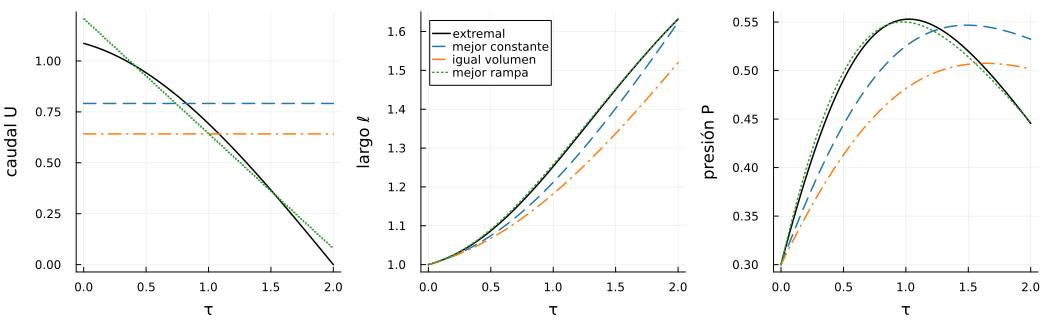

figuras: comparacion.png, 62 KB


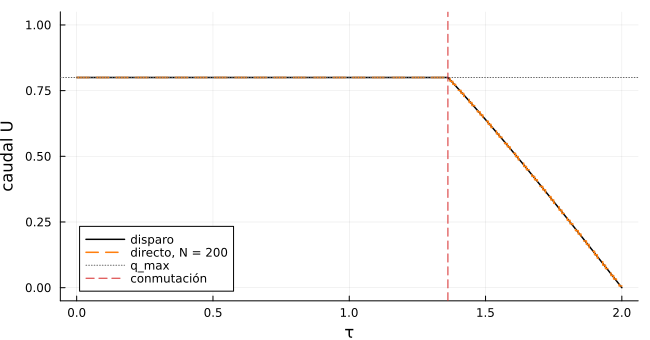

figuras: cota-activa.png, 21 KB


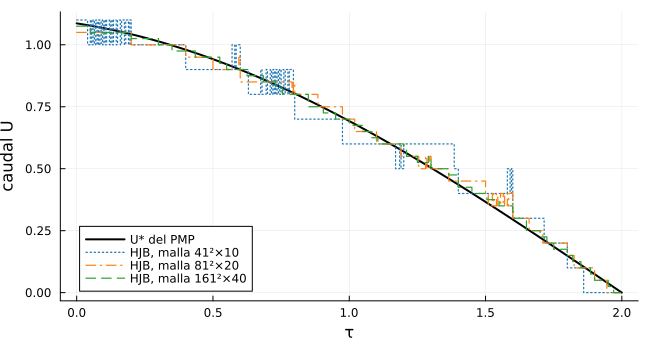

figuras: retroalimentacion.png, 38 KB


In [29]:
mostrar_figuras(df)

## Referencia: las cifras del reporte entregado

In [30]:
# Las 57 cifras del reporte entregado, copiadas por notebook/derivar.py de avance/reporte/cifras.tex
# (sha256 a4fdfc1b65f95b91c6f9d6f2cde4a053e5a67dc13be202e23d8681251b523ed9). Se comparan como texto con las recién calculadas, salvo las de RUIDO (abajo),
# que se comparan en orden de magnitud. Cualquier otra diferencia, aunque sea en la última cifra, se lista y da error. Va al final para que, aun con error, todas las
# salidas ya estén escritas.
const REFERENCIA = [
    "parn" => "2",
    "parc" => "1",
    "pareta" => "0{,}2",
    "parellcero" => "1",
    "parPcero" => "0{,}3",
    "parT" => "2",
    "parLd" => "1{,}7",
    "parwT" => "10",
    "parwp" => "1",
    "parwq" => "0{,}2",
    "parqmax" => "2",
    "maxU" => "1{,}09",
    "nSim" => "27",
    "nConj" => "\\{1;\\,2;\\,3\\}",
    "etaConj" => "\\{0;\\,0{,}2;\\,1\\}",
    "UConj" => "\\{0;\\,0{,}5;\\,1\\}",
    "Tbarrido" => "10",
    "resBalance" => "2\\cdot10^{-12}",
    "Jstar" => "0{,}371862",
    "resDisparo" => "4\\cdot10^{-15}",
    "Hosc" => "3\\cdot10^{-15}",
    "razonBrecha" => "4{,}0",
    "Nprimero" => "25",
    "Nultimo" => "200",
    "brechaPrimero" => "3{,}5\\cdot10^{-5}",
    "brechaUltimo" => "5{,}4\\cdot10^{-7}",
    "filasTabla" => "Directo, \$N=200\$ (aprox.~del extremal) & 0{,}371863 & --- & 0{,}0233 & 0{,}2448 & 0{,}1038 & 1{,}284 & 1{,}632\\\\\nMejor rampa lineal escalonada, \$N=200\$ & 0{,}372255 & 0{,}11\\,\\% & 0{,}0234 & 0{,}2448 & 0{,}1041 & 1{,}287 & 1{,}632\\\\\nMejor constante, \$U=0{,}791\$ & 0{,}396738 & 6{,}7\\,\\% & 0{,}0291 & 0{,}2423 & 0{,}1253 & 1{,}583 & 1{,}624\\\\\nConstante de igual volumen, \$U=0{,}642\$ & 0{,}453500 & 22\\,\\% & 0{,}1617 & 0{,}2094 & 0{,}0824 & 1{,}284 & 1{,}520\\\\",
    "Ufactible" => "0{,}901",
    "igualVolPct" => "22",
    "picoP" => "0{,}553",
    "picoT" => "1{,}02",
    "PTconst" => "0{,}53",
    "PTopt" => "0{,}45",
    "ellIgual" => "1{,}520",
    "rampaA" => "1{,}21",
    "rampaB" => "0{,}08",
    "rampaPct" => "0{,}11",
    "qmaxCota" => "0{,}8",
    "conmutacion" => "1{,}362",
    "dJcota" => "8\\cdot10^{-7}",
    "cotaPct" => "2{,}65",
    "Jterminal" => "0{,}396306",
    "nu" => "0{,}717",
    "wTprimero" => "10",
    "wTultimo" => "10^{4}",
    "razonesDecada" => "9{,}2;\\ 9{,}9;\\ 10{,}0",
    "domEll" => "[1;\\,2{,}55]",
    "domP" => "[0;\\,1{,}2]",
    "errVA" => "1{,}59",
    "mallaA" => "41^2\\times10",
    "errVB" => "0{,}73",
    "mallaB" => "81^2\\times20",
    "errVC" => "0{,}34",
    "mallaC" => "161^2\\times40",
    "dJlazo" => "5{,}2\\cdot10^{-5}",
    "zetaEll" => "1{,}0",
    "zetaP" => "3{,}2",
]


# Cifras que son ruido de redondeo (residuos y oscilaciones del orden de 1e-12 a 1e-15): su última cifra depende del
# procesador y de las versiones de las dependencias, no del modelo. Para ellas basta el orden de magnitud: la nueva no
# puede pasar de 10 veces la del reporte. Las demás se comparan como texto, exactas.
const RUIDO = ("resBalance", "resDisparo", "Hosc")

function valor_potencia(s)
    m = match(r"^(?:([0-9]+(?:\{,\}[0-9]+)?)\\cdot)?10\^\{(-?[0-9]+)\}$", s)
    m === nothing && error("referencia: «$s» no es de la forma a\\cdot10^{e}")
    a = m[1] === nothing ? 1.0 : parse(Float64, replace(m[1], "{,}" => "."))
    return a * 10.0^parse(Int, m[2])
end

function comparar_referencia(c, ref = REFERENCIA)
    nuevas = Dict(c)
    malas = String[]
    for (k, v) in ref
        if !haskey(nuevas, k)
            push!(malas, "$k: falta en lo recién calculado")
        elseif nuevas[k] == v
            continue
        elseif k in RUIDO && valor_potencia(nuevas[k]) <= 10 * valor_potencia(v)
            println("  RUIDO      $k: el reporte dice «$v», ahora sale «$(nuevas[k])» (mismo orden o menor: se acepta)")
        else
            push!(malas, "$k: el reporte dice «$v», ahora sale «$(nuevas[k])»")
        end
    end
    foreach(k -> push!(malas, "$k: no está en el reporte"), setdiff(first.(c), first.(ref)))
    foreach(m -> println("  DISTINTA  ", m), malas)
    println("referencia: $(length(ref)) cifras del reporte, $(length(malas)) distintas")
    isempty(malas) || error("referencia: lo calculado no coincide con el reporte entregado")
end


comparar_referencia (generic function with 2 methods)

In [31]:
comparar_referencia(cf)

referencia: 57 cifras del reporte, 0 distintas


true